# **Sites fédéraux recensés au FCSI et gouvernance territoriale autochtone : le rôle du Framework Agreement on First Nation Land Management**

**Tran Nguyen Quoc-Long — Projet supervisé, M. Sc. finance, HEC Montréal**

Les titres de section renvoient entre parenthèses aux sections du rapport (Rapport_FCSI_FNLM_v21.docx).

# Partie 1 — Données et construction de l’échantillon

## 1.1 Préparation, outils d’affichage et listes de colonnes

**Fonctions utilitaires**

`nettoyer_nom` met un libellé sous forme comparable : décomposition Unicode pour retirer les accents, suppression des apostrophes, passage en minuscules et conservation des seuls caractères alphanumériques. C'est elle qui rend l'appariement robuste aux variantes d'écriture. `filtres_groupes` renvoie les trois masques de catégories, `montrer_tableau` applique un format par colonne et un style HTML commun, 

**Données et méthodologie**

Cette cellule déclare les listes de colonnes du FCSI mobilisées plus loin : les quatre postes de dépenses, les trois quantités remédiées, les quatre classes analysées et les champs supposés constants pour un site. `COLONNES_FCSI_NECESSAIRES` les réunit en un ensemble qui sert de contrôle au chargement : si une colonne manque, l'exécution s'arrête avant l'analyse.

### Importation des paquets

In [1]:
import re, unicodedata
from pathlib import Path
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

### Importation des données

In [2]:
CHEMIN_FCSI = Path("GovofCanada_FCSI_AllProvinces_CombinedData_2023.dta")

fcsi_original = pd.read_stata(CHEMIN_FCSI)
nombre_observations, nombre_variables = fcsi_original.shape

print(f"Observations : {nombre_observations:,} | Variables : {nombre_variables}")

Observations : 197,025 | Variables : 44


### Fonctions pour tableau

In [3]:

def nettoyer_nom(texte):

    texte = unicodedata.normalize("NFKD", str(texte))
    texte = "".join(c for c in texte if not unicodedata.combining(c))
    texte = texte.replace("'", "").replace("’", "").replace("‘", "").replace("`", "")
    texte = texte.lower().replace("&", " and ")
    return " ".join(re.findall(r"[a-z0-9]+", texte))

assert nettoyer_nom("Aq’am") == "aqam"
assert nettoyer_nom("Tsleil-Waututh") == "tsleil waututh"

def filtres_groupes(table_sites):

    return {
        "Réserve + FNLM": table_sites["reserve_lma"].eq(1),
        "Réserve sans FNLM": table_sites["reserve_non_lma"].eq(1),
        "Hors réserve": table_sites["est_reserve"].eq(0),
    }

STYLE_AFFICHAGE = """
<style>
  .tableau-fnlm {border-collapse: collapse; font-size: 13px; margin: 8px 0 18px 0;}
  .tableau-fnlm th {background: #1F4E78; color: white; padding: 7px 10px; text-align: center;}
  .tableau-fnlm td {padding: 6px 10px; text-align: center; border-bottom: 1px solid #D9E2F3;}
  .tableau-fnlm tbody tr:nth-child(even) {background: #EAF2F8;}
  .titre-tableau-fnlm {font-size: 15px; font-weight: 700; color: #1F4E78; margin-top: 8px;}
</style>
"""

def montrer_tableau(table, formats=None, titre=None):

    table_affichee = table.copy()
    for colonne, format_case in (formats or {}).items():
        if colonne in table_affichee.columns:
            table_affichee[colonne] = table_affichee[colonne].map(
                lambda v: "—" if pd.isna(v) else format_case.format(v)
            )
    bloc_titre = f'<div class="titre-tableau-fnlm">{titre}</div>' if titre else ""
    display(HTML(
        STYLE_AFFICHAGE
        + bloc_titre
        + table_affichee.to_html(index=False, border=0, classes="tableau-fnlm", escape=False)
    ))

### Données et méthodologies

In [4]:
COLONNES_DEPENSES = [
    "totalassessmentexpenditure", "totalremediationexpenditure",
    "totalcaremaintenanceexpenditure", "totalmonitoringexpenditure",
]
COLONNES_QUANTITES = [
    "actualcubicmetersremediated", "actualhectaresremediated", "actualtonsremediated",
]
CLASSES_ANALYSEES = [
    "High Priority for Action", "Medium Priority for Action",
    "Low Priority for Action", "Not a Priority for Action",
]
CHAMPS_FIXES_SITE = [
    "sitename", "sitestatus", "class", "mediumcontaminants",
    "reportingorganization", "province", "involvement",
]
COLONNES_FCSI_NECESSAIRES = {
    "federalsiteidentifier", "fiscalyear", "closed", "higheststepcompleted",
    *CHAMPS_FIXES_SITE, *COLONNES_DEPENSES, *COLONNES_QUANTITES,
}

## 1.2 Du panel FCSI à une base de sites  *(rapport 3.1)*

`retirer_doublons_annuels` ramène le fichier à une ligne par couple site-exercice. Elle vérifie d'abord qu'aucun doublon ne se contredit sur les champs descriptifs et lève une erreur si c'est le cas. Elle conserve ensuite la dernière ligne de chaque groupe, remplace les colonnes numériques par leur maximum et fusionne le champ `closed` en retenant `True` dès qu'il apparaît une fois.

**Statistiques par groupe**

`calculer_stats_groupes` produit une ligne par catégorie de site. Pour chacune, elle compte les sites, la part de classifications informatives, les moyennes des issues et la couverture de l'étape. Elle n'est appelée qu'une fois, sur l'échantillon analytique ; sa sortie alimente le tableau des statistiques descriptives de la section 1.8, la figure 4.1 et le tableau des étapes de la section 4.6.



### Définir doublons et statistiques 

In [5]:
def retirer_doublons_annuels(df):
    cle = ["federalsiteidentifier", "fiscalyear"]
    doublons = df[df.duplicated(cle, keep=False)]
    for colonne in CHAMPS_FIXES_SITE:
        conflits = doublons.groupby(cle, dropna=False)[colonne].nunique(dropna=False).gt(1).sum()
        if conflits:
            raise AssertionError(f"{conflits} doublon(s) divergent pour {colonne}.")

    propre = df.groupby(cle, dropna=False, sort=False).tail(1).copy().set_index(cle)
    numeriques_max = ["higheststepcompleted"] + COLONNES_DEPENSES + COLONNES_QUANTITES
    propre[numeriques_max] = (
        df.groupby(cle, dropna=False, sort=False)[numeriques_max].max()
        .reindex(propre.index).astype(float)
    )
    propre["closed"] = (
        df.groupby(cle, dropna=False, sort=False)["closed"]
        .agg(lambda v: "True" if v.eq("True").any() else ("False" if v.eq("False").any() else ""))
        .reindex(propre.index).astype(str)
    )
    propre = propre.reset_index()
    assert not propre.duplicated(cle).any(), "La déduplication a échoué."
    return propre



### Statistique par groupe

In [6]:
def calculer_stats_groupes(echantillon_final):
    lignes = []
    for libelle, masque in filtres_groupes(echantillon_final).items():
        d = echantillon_final[masque]
        etape_disponible = d["higheststepcompleted"].notna()
        lignes.append(
            {
                "groupe": libelle,
                "N_sites": len(d),
                "N_classe_valide": int(d["classification_disponible"].sum()),
                "couverture_classe": d["classification_disponible"].mean(),
                "priorite_action": d["priorite_action"].mean(),
                "haute_priorite_action": d["haute_priorite_action"].mean(),
                "statut_actif": d["statut_actif"].mean(),
                "statut_ferme": d["sitestatus"].eq("Closed").mean(),
                "N_etape_valide": int(etape_disponible.sum()),
                "couverture_etape": etape_disponible.mean(),
                "etape_moyenne": d["higheststepcompleted"].mean(),
                "etape_9_plus": d.loc[
                    etape_disponible, "higheststepcompleted"
                ].ge(9).mean(),
            }
        )
    return pd.DataFrame(lignes)

### Chargement et contrôle des colonnes

In [7]:

champs_absents = sorted(COLONNES_FCSI_NECESSAIRES.difference(fcsi_original.columns))
if champs_absents:
    raise ValueError(f"Colonnes FCSI manquantes : {champs_absents}")
fcsi_nettoye = retirer_doublons_annuels(fcsi_original)
variations_interet = (
    fcsi_nettoye.groupby("federalsiteidentifier")[["class", "sitestatus"]]
    .nunique(dropna=False)
    .gt(1)
    .sum()
)
if variations_interet.any():
    raise AssertionError(
        "Variation temporelle inattendue de class ou sitestatus : "
        f"{variations_interet[variations_interet.gt(0)].to_dict()}"
    )

print(f"Observations brutes                  : {len(fcsi_original):,}")
print(f"Doublons site-exercice en excès      : {len(fcsi_original) - len(fcsi_nettoye):,}")
print(f"Observations site-exercice nettoyées : {len(fcsi_nettoye):,}")

Observations brutes                  : 197,025
Doublons site-exercice en excès      : 2,071
Observations site-exercice nettoyées : 194,954


### base de sites

In [8]:
fcsi_nettoye["annee_debut"] = pd.to_numeric(
    fcsi_nettoye["fiscalyear"].astype(str).str.extract(r"^(\d{4})")[0],
    errors="coerce",
)
panel_fcsi_complet = fcsi_nettoye[fcsi_nettoye["annee_debut"].notna()].copy()
base_sites_fcsi = (
    fcsi_nettoye.sort_values("annee_debut", na_position="first", kind="stable")
    .groupby("federalsiteidentifier", as_index=False)
    .tail(1)
    .copy()
)

print(f"Nombre de sites distincts : {len(base_sites_fcsi):,}")
print(f"Période observée           : {int(panel_fcsi_complet['annee_debut'].min())}–{int(panel_fcsi_complet['annee_debut'].max())}")
display(base_sites_fcsi[["federalsiteidentifier", "sitename", "province", "sitestatus", "class"]].head())


Nombre de sites distincts : 23,848
Période observée           : 1993–2022


,federalsiteidentifier,sitename,province,sitestatus,class
8008,00028025,Peace River at Peace Point,Alberta,Suspected,Medium Priority for Action
8009,00025130,Edmonton - Small Arms Range,Alberta,Suspected,
8010,00025104,408 Sqn Parking Lot,Alberta,Suspected,
48531,00025111,MH-8 Mary Hill Training Area,British Columbia,Suspected,
48532,00025110,Belmont Park,British Columbia,Suspected,


### Identification des sites situés sur une réserve  *(rapport 3.1.2)*


In [9]:
base_sites_fcsi["est_reserve"] = (base_sites_fcsi["involvement"] == "A reserve as defined in the Indian Act" ).astype(int)
print(f"Sites sur réserve avant exclusion : {int(base_sites_fcsi['est_reserve'].sum()):,}")
print(f"Sites hors réserve                : {int(base_sites_fcsi['est_reserve'].eq(0).sum()):,}")

Sites sur réserve avant exclusion : 4,550
Sites hors réserve                : 19,298


## 1.3 Indicateur FNLM — données de référence (étapes 1 à 4)  *(rapport 3.2, tableau 3.2)*

Cette partie construit l’indicateur FNLM utilisé dans les analyses.



### **Étape 1 : Ajouter les dates d’entrée en vigueur**

In [10]:
NUMERO_EN_TETE = re.compile(r"^\s*0*(\d{1,3})\s*[-–]\s*")
SEPARATEUR_TIRET = re.compile(r"\s+[-–]\s+")
SUFFIXE_CODE_SITE = re.compile(r"\s*\(?\d{5}\)?\s*$")

def trouver_info_bande(libelle_site):

    texte = "" if pd.isna(libelle_site) else str(libelle_site).strip()
    numero_detecte = NUMERO_EN_TETE.match(texte)
    numero = int(numero_detecte.group(1)) if numero_detecte else None

    if numero is not None:
        reste = texte[numero_detecte.end():]
        nom_bande = SEPARATEUR_TIRET.split(reste, maxsplit=1)[0]
    else:
        morceaux_nom = SEPARATEUR_TIRET.split(texte)
        nom_bande = texte
        if len(morceaux_nom) >= 2 and SUFFIXE_CODE_SITE.search(morceaux_nom[0]):
            nom_bande = morceaux_nom[0]

    return numero, nettoyer_nom(SUFFIXE_CODE_SITE.sub("", nom_bande).strip())

assert trouver_info_bande("136 - Wasauksing First Nation - 06205 - PARRY ISLAND") == (
    136, "wasauksing first nation"
)
assert trouver_info_bande("Katzie (08024) - site") == (None, "katzie")

exemple_extraction = base_sites_fcsi.loc[
    base_sites_fcsi["est_reserve"].eq(1), ["sitename"]
].head(8).copy()
exemple_extraction[["numero_bande", "nom_bande_normalise"]] = pd.DataFrame(
    exemple_extraction["sitename"].map(trouver_info_bande).tolist(),
    index=exemple_extraction.index,
)
display(exemple_extraction)

,sitename,numero_bande,nom_bande_normalise
51877,306 - Tataskweyak Cree Nation - 06461 - SPLIT ...,306,tataskweyak cree nation
131073,136 - Wasauksing First Nation - 06205 - PARRY ...,136,wasauksing first nation
131074,136 - Wasauksing First Nation - 06205 - PARRY ...,136,wasauksing first nation
3150,437 - Alexis Nakota Sioux Nation - 06649 - ALE...,437,alexis nakota sioux nation
3151,450 - Driftpile First Nation - 06677 - DRIFT P...,450,driftpile first nation
3152,430 - Siksika Nation - 06636 - SIKSIKA INDIAN ...,430,siksika nation
3153,433 - Chiniki - 06642 - STONEY NO. 142-143-144...,433,chiniki
3155,458 - Bigstone Cree Nation - 06691 - WABASCA N...,458,bigstone cree nation


### Étape 2 : Préparer la liste des Nations FNLM

In [11]:
NOMS_FNLM_CONNUS = {
    'abenakis de wolinak', 'aitchelitz', 'alderville', 'algonquins of pikwakanagan',
    'animbiigoo zaagiigan anishinaabek', 'anishinaabeg of naongashiing', 'anishnaabeg of naongashiing', 'aqam',
    'atikameksheng anishnawbek', 'beausoleil', 'beecher bay', 'big grassy river',
    'biinjitiwaabik zaaging anishinaabek', 'bingwi neyaashi anishinaabek', 'brokenhead', 'brokenhead ojibway nation',
    'brunswick house', 'burrard', 'campbell river', 'cape mudge',
    'chawathil', 'cheam', 'chemawawin', 'chippewas of georgina island',
    'chippewas of rama', 'cowichan', 'cowichan tribes', 'ditidaht',
    'doig river', 'dokis', 'esquimalt', 'fisher river',
    'fisher river cree nation', 'fishing lake', 'flying dust', 'fort alexander',
    'fort mckay', 'gambler', 'george gordon', 'haisla',
    'henvey inlet', 'hiawatha', 'homalco', 'iskut',
    'kahkewistahaw', 'katlodeeche', 'katzie', 'kinistin',
    'kinistin saulteaux', 'kitselas', 'kitsumkalum', 'komoks',
    'kwantlen', 'kwaw kwaw apilt', 'kwiakah', 'kwikwetlem',
    'lac la ronge', 'lake cowichan', 'leq a mel', 'leqa mel',
    'leqamel', 'lheidli tenneh', 'long lake 58', 'long lake no 58',
    'long plain', 'lower nicola', 'lytton', 'madawaska',
    'madawaska maliseet', 'magnetawan', 'malahat', 'mashteuiatsh',
    'matsqui', 'mcleod lake', 'membertou', 'metlakatla',
    'miawpukek', 'misipawistik', 'misipawistik cree nation', 'missanabie cree',
    'mississauga', 'mississauga first nation', 'mississaugas of scugog island', 'mistawasis',
    'mitaanjigamiing', 'montagnais du lac st jean', 'montreal lake', 'montreal lake cree nation',
    'moose deer point', 'musk kosiminiziibing', 'muskeg lake', 'muskeg lake cree nation',
    'muskoday', 'musqueam', 'nakazdli', 'nakazdli whuten',
    'namgis', 'nanoose', 'nipissing', 'nisichawayasihk',
    'nisichawayasihk cree nation', 'one arrow', 'opaskwayak', 'opaskwayak cree nation',
    'paqtnkek', 'pavilion', 'peerless trout', 'peguis',
    'pekuakamiulnuatsh', 'penelakut', 'popkum', 'rainy river',
    'rainy river first nations', 'rama', 'roseau river', 'sagkeeng',
    'sakimay', 'sandy bay ojibway', 'scianew', 'scugog island',
    'seabird island', 'semiahmoo', 'shawanaga', 'sheshegwaning',
    'shuswap', 'shxwha y village', 'shxwhay', 'shxwhay village',
    'shxwowhame', 'shxwowohamel', 'skawahlook', 'skowkale',
    'skwah', 'sliammon', 'snaw naw as', 'songhees',
    'soowahlie', 'sqewlets', 'squiala', 'sqwa',
    'stanjikoming', 'stsailes', 'stzuminus', 'stzuminus first nation',
    'sumas', 'swan lake', 'temagami', 'teme augama',
    'titqet', 'tlaamin', 'tlaamin nation', 'tobacco plains',
    'tsawout', 'tsawout first nation', 'tsawwassen', 'tseycum',
    'tskwaylaxw', 'tsleil waututh', 'tsleil waututh nation', 'tsou ke',
    'tsouke', 'tsuubaa asatx', 'tzeachten', 'wahnapitae',
    'wasauksing', 'we wai kai', 'wei wai kum', 'westbank',
    'westbank first nation', 'whitecap dakota', 'williams lake', 'wolinak',
    'woodland cree', 'xeni gwetin', 'yakweakwioose', 'yaqit aknuqliit',
    'yellow quill', 'zagime anishinabek',
}
NOMS_FNLM_TRIES = sorted(NOMS_FNLM_CONNUS, key=lambda x: (-len(x), x))

###  Étape 3: Noms ambigus à vérifier

In [12]:

NOMS_FNLM_AMBIGUS = {
    nettoyer_nom(x)
    for x in ["mississauga", "shuswap", "saulteaux", "alexander"]
}

EQUIVALENCES_HISTORIQUES = {
    nettoyer_nom(k): nettoyer_nom(v)
    for k, v in {
        "fort alexander": "sagkeeng",
        "montagnais du lac st jean": "pekuakamiulnuatsh",
        "montagnais du lac st. jean": "pekuakamiulnuatsh",
        "sakimay first nations": "zagime anishinabek",
        "sumas first nation": "sumas",
        "shxwowhamel first nation": "shxwowhame",
        "sandy bay": "sandy bay ojibway",
        "big grassy": "big grassy river",
    }.items()
}

NOMS_EXCLUS = {
    nettoyer_nom(x)
    for x in [
        "mississaugas of the credit",
        "little shuswap lake",
        "saulteaux",
        "alexander",
        "esquimalt harbour fill sites",
        "fisher river near dallas",
    ]
}

NOMS_AUTONOMIE = {
    nettoyer_nom(x)
    for x in [
        "sliammon",
        "tlaamin",
        "tlaamin nation",
        "tsawwassen",
        "westbank",
        "westbank first nation",
        "whitecap",
        "whitecap dakota",
        "whitecap dakota first nation",
    ]
}

### Étape 4: Date d'entrée en vigueur

In [13]:
# Source principale : annexe 2 de l'ancienne Loi sur la gestion des terres des premières nations,
# version archivée au 18 mars 2021 — dates d'entrée en vigueur des codes fonciers :
# https://laws-lois.justice.gc.ca/fra/lois/F-11.8/section-sched221804-20210318.html?wbdisable=true
# Les clés supplémentaires sont des alias normalisés servant à l'appariement avec les noms du FCSI.
DATES_FONCIERES = {
    'algonquins of pikwakanagan': '2019-08-01', 'atikameksheng': '2009-03-01', 'beausoleil': '2019-11-01',
    'anishnaabeg of naongashiing': '2011-08-01', 'naongashiing': '2011-08-01', 'bingwi neyaashi': '2015-04-01',
    'brunswick house': '2019-10-01', 'chippewas of georgina island': '2000-01-01', 'chippewas of rama': '2018-05-01',
    'rama': '2018-05-01', 'dokis': '2014-04-01', 'henvey inlet': '2010-01-01',
    'long lake no 58': '2017-04-01', 'long lake 58': '2017-04-01', 'magnetawan': '2015-09-01',
    'mississaugas of scugog island': '2000-01-01', 'scugog island': '2000-01-01', 'mississauga first nation': '2009-08-01',
    'mississauga': '2009-08-01', 'moose deer point': '2020-06-01', 'nipissing': '2003-07-01',
    'shawanaga': '2015-07-01', 'sheshegwaning': '2019-10-01', 'temagami': '2017-09-01',
    'wasauksing': '2017-06-01', 'abenakis de wolinak': '2017-04-01', 'wolinak': '2017-04-01',
    'membertou': '2019-09-01', 'madawaska maliseet': '2018-01-01', 'madawaska': '2018-01-01',
    'brokenhead': '2015-04-01', 'chemawawin': '2010-09-06', 'long plain': '2018-04-01',
    'misipawistik': '2017-06-01', 'nisichawayasihk': '2017-10-23', 'swan lake': '2010-10-01',
    'opaskwayak': '2002-08-01', 'aitchelitz': '2014-05-01', 'aqam': '2014-07-01',
    'beecher bay': '2003-08-01', 'scianew': '2003-08-01', 'campbell river': '2013-01-31',
    'wei wai kum': '2013-01-31', 'chawathil': '2016-11-25', 'cheam': '2016-09-01',
    'cowichan tribes': '2019-11-01', 'ditidaht': '2019-12-01', 'lheidli tenneh': '2000-11-01',
    'haisla': '2015-11-06', 'homalco': '2019-12-01', 'katzie': '2017-12-01',
    'kitselas': '2005-11-25', 'kitsumkalum': '2020-02-01', 'komoks': '2016-11-30',
    'kwantlen': '2015-11-01', 'kwaw kwaw apilt': '2018-06-01', 'kwikwetlem': '2020-07-01',
    'lake cowichan': '2017-06-09', 'tsuubaa asatx': '2017-06-09', 'leqamel': '2010-02-01',
    'leq a mel': '2010-02-01', 'lower nicola': '2016-12-01', 'malahat': '2015-03-31',
    'matsqui': '2009-02-26', 'mcleod lake': '2003-05-20', 'metlakatla': '2016-12-01',
    'musqueam': '2017-06-05', 'nakazdli': '2016-12-01', 'namgis': '2019-04-01',
    'nanoose': '2015-03-01', 'snaw naw as': '2015-03-01', 'pavilion': '2004-05-01',
    'tskwaylaxw': '2004-05-01', 'penelakut': '2020-02-01', 'scowlitz': '2016-09-01',
    'sqewlets': '2016-09-01', 'seabird island': '2009-09-01', 'shuswap': '2015-02-01',
    'shxwhay': '2007-01-08', 'shxwowhamel': '2015-03-25', 'shxwowhame': '2015-03-25',
    'skawahlook': '2010-08-05', 'skowkale': '2014-05-01', 'songhees': '2011-10-01',
    'soowahlie': '2016-06-01', 'squiala': '2008-07-29', 'stsailes': '2018-10-23',
    'stzuminus': '2014-08-30', 'sumas': '2011-11-11', 'titqet': '2019-09-01',
    'tsawout': '2007-05-29', 'tsleil waututh': '2007-06-06', 'tsouke': '2007-02-01',
    'tsou ke': '2007-02-01', 'tzeachten': '2008-08-21', 'we wai kai': '2009-12-07',
    'cape mudge': '2009-12-07', 'williams lake': '2014-07-01', 'yakweakwioose': '2014-05-01',
    'flying dust': '2013-10-06', 'muskoday': '2000-01-01', 'kahkewistahaw': '2011-12-22',
    'kinistin': '2005-02-01', 'lac la ronge': '2020-02-19', 'mistawasis': '2017-04-01',
    'muskeg lake': '2005-09-01', 'one arrow': '2014-09-01', 'yellow quill': '2017-03-22',
    'miawpukek': '2017-12-01',
}
DATES_FONCIERES.update({

    "cowichan": "2019-11-01",
    "shxwha y village": "2007-01-08",
    "leqa mel": "2010-02-01",    
    "shxwowohamel": "2015-03-25",   
})
DATES_FONCIERES = {nettoyer_nom(k): pd.Timestamp(v) for k, v in DATES_FONCIERES.items()}
NOMS_DATES_TRIES = sorted(DATES_FONCIERES, key=lambda x: (-len(x), x))

def trouver_date_fnlm(nom):
    if not nom:
        return pd.NaT
    nom_avec_espaces = f" {nom} "
    for nom_repere in NOMS_DATES_TRIES:
        if nom == nom_repere:
            return DATES_FONCIERES[nom_repere]
        if nom_repere in NOMS_FNLM_AMBIGUS or len(nom_repere) < 6:
            continue
        if f" {nom_repere} " in nom_avec_espaces:
            return DATES_FONCIERES[nom_repere]
    return pd.NaT

assert trouver_date_fnlm("aqam") == pd.Timestamp("2014-07-01")
assert trouver_date_fnlm("scugog island") == pd.Timestamp("2000-01-01")
assert trouver_date_fnlm("muskoday") == pd.Timestamp("2000-01-01")
print(f"Variantes FNLM normalisées : {len(NOMS_FNLM_CONNUS)}")
print(f"Équivalences historiques   : {len(EQUIVALENCES_HISTORIQUES)}")
print(f"Repères de dates disponibles: {len(DATES_FONCIERES)}")

Variantes FNLM normalisées : 178
Équivalences historiques   : 7
Repères de dates disponibles: 113


## 1.4 Indicateur FNLM — appariement (étapes 5 à 8)  *(rapport 3.2)*



###  Étape 5 : Faire l’appariement principal par nom

In [14]:

def classer_nom_fnlm(nom):
    
    if not nom:
        return 0, "aucun", ""
    if nom in NOMS_EXCLUS:
        return 0, "exclusion manuelle", ""
    if nom in EQUIVALENCES_HISTORIQUES:
        return 1, "équivalence historique", EQUIVALENCES_HISTORIQUES[nom]
    if nom in NOMS_FNLM_CONNUS:
        return 1, "exacte", nom

    nom_avec_espaces = f" {nom} "
    for alias in NOMS_FNLM_TRIES:
        if alias in NOMS_FNLM_AMBIGUS or len(alias) < 6:
            continue
        if f" {alias} " in nom_avec_espaces:
            return 1, "inclusion de mots", alias
    return 0, "aucun", ""

assert classer_nom_fnlm("aqam") == (1, "exacte", "aqam")
assert classer_nom_fnlm("fort alexander") == (1, "équivalence historique", "sagkeeng")
assert classer_nom_fnlm("little shuswap lake") == (0, "exclusion manuelle", "")

infos_bandes = base_sites_fcsi["sitename"].map(trouver_info_bande)
base_sites_fcsi["numero_bande"] = pd.array(
    [x[0] if r == 1 else pd.NA for x, r in zip(infos_bandes, base_sites_fcsi["est_reserve"])],
    dtype="Int64",
)
base_sites_fcsi["nom_bande_normalise"] = [
    x[1] if r == 1 else "" for x, r in zip(infos_bandes, base_sites_fcsi["est_reserve"])
]

resultats_appariement = base_sites_fcsi["nom_bande_normalise"].map(classer_nom_fnlm)
base_sites_fcsi[["est_fnlm_courant", "methode_appariement", "alias_apparie"]] = pd.DataFrame(
    resultats_appariement.tolist(), index=base_sites_fcsi.index
)


###  Étape 6 : Compléter l’appariement avec le numéro de bande

In [15]:

filtre_reserves = base_sites_fcsi["est_reserve"].eq(1)

for numero, groupe in base_sites_fcsi[
    filtre_reserves & base_sites_fcsi["numero_bande"].notna()
    
].groupby("numero_bande"):
    lignes_valides = groupe[groupe["est_fnlm_courant"].eq(1)]
    if lignes_valides.empty:
        continue

    alias = lignes_valides["alias_apparie"].replace("", pd.NA).dropna().mode()
    alias = alias.iloc[0] if len(alias) else ""
    lignes_a_completer = groupe.index[groupe["est_fnlm_courant"].eq(0)]

    base_sites_fcsi.loc[
        lignes_a_completer,
        ["est_fnlm_courant", "methode_appariement", "alias_apparie"],
    ] = [1, "propagation par numéro de bande", alias]


### Étape 7 : Repérer les Nations en autonomie gouvernementale

In [16]:

base_sites_fcsi["autonomie_gouvernementale"] = base_sites_fcsi["nom_bande_normalise"].map(
    lambda x: int(any(a == x or f" {a} " in f" {x} " for a in NOMS_AUTONOMIE))
)
bandes_autonomes = set(
    base_sites_fcsi.loc[
        base_sites_fcsi["autonomie_gouvernementale"].eq(1)
        & base_sites_fcsi["numero_bande"].notna(),
        "numero_bande",
    ].astype(int)
)
base_sites_fcsi.loc[
    base_sites_fcsi["numero_bande"].isin(bandes_autonomes),
    "autonomie_gouvernementale",
] = 1

### Étape 8 : Attribuer le statut et la date FNLM aux sites

In [17]:

filtre_fnlm = filtre_reserves & base_sites_fcsi["est_fnlm_courant"].eq(1)
base_sites_fcsi["date_entree_vigueur_code"] = pd.NaT
dates_depuis_nom = base_sites_fcsi.loc[filtre_fnlm, "nom_bande_normalise"].map(trouver_date_fnlm)
dates_depuis_alias = base_sites_fcsi.loc[filtre_fnlm, "alias_apparie"].map(trouver_date_fnlm)
base_sites_fcsi.loc[filtre_fnlm, "date_entree_vigueur_code"] = dates_depuis_alias.fillna(dates_depuis_nom)
dates_par_bande = (
    base_sites_fcsi.loc[filtre_fnlm]
    .dropna(subset=["numero_bande", "date_entree_vigueur_code"])
    .groupby("numero_bande")["date_entree_vigueur_code"]
    .min()
)

filtre_dates_a_completer = (
    filtre_fnlm
    & base_sites_fcsi["date_entree_vigueur_code"].isna()
    & base_sites_fcsi["numero_bande"].notna()
)

base_sites_fcsi.loc[filtre_dates_a_completer, "date_entree_vigueur_code"] = base_sites_fcsi.loc[
    filtre_dates_a_completer, "numero_bande"
].map(dates_par_bande)
base_sites_fcsi.loc[~filtre_fnlm, "date_entree_vigueur_code"] = pd.NaT

bilan_appariement = base_sites_fcsi.loc[
    base_sites_fcsi["est_reserve"].eq(1), "methode_appariement"
].value_counts().rename_axis("Méthode").reset_index(name="Sites")

montrer_tableau(bilan_appariement, formats={"Sites": "{:,}"}, titre="Audit synthétique de l'appariement")
print(f"Sites FNLM identifiés avant exclusion : {int(base_sites_fcsi['est_fnlm_courant'].sum()):,}")
print(f"Sites d'autonomie gouvernementale     : {int(base_sites_fcsi['autonomie_gouvernementale'].sum()):,}")

Sites FNLM identifiés avant exclusion : 1,179
Sites d'autonomie gouvernementale     : 47


Méthode,Sites
aucun,"3,351"
exacte,736
inclusion de mots,366
équivalence historique,69
exclusion manuelle,20
propagation par numéro de bande,8


## 1.5 Variables et échantillon d’analyse  *(rapport 3.3 et 3.7, tableau 3.4)*



In [18]:
base_sites_fcsi["inclus_analyse_principale"] = base_sites_fcsi[
    "autonomie_gouvernementale"
].eq(0).astype(int)
base_sites_fcsi["reserve_lma"] = (
    base_sites_fcsi["inclus_analyse_principale"].eq(1)
    & base_sites_fcsi["est_reserve"].eq(1)
    & base_sites_fcsi["est_fnlm_courant"].eq(1)
).astype(int)
base_sites_fcsi["reserve_non_lma"] = (
    base_sites_fcsi["inclus_analyse_principale"].eq(1)
    & base_sites_fcsi["est_reserve"].eq(1)
    & base_sites_fcsi["est_fnlm_courant"].eq(0)
).astype(int)
echantillon_final = base_sites_fcsi[base_sites_fcsi["inclus_analyse_principale"].eq(1)].copy()

filtre_classes = echantillon_final["class"].isin(CLASSES_ANALYSEES)
echantillon_final["classification_disponible"] = filtre_classes.astype(int)
echantillon_final["priorite_action"] = np.where(
    filtre_classes,
    echantillon_final["class"].isin(CLASSES_ANALYSEES[:3]).astype(float),
    np.nan,
)
echantillon_final["haute_priorite_action"] = np.where(
    filtre_classes,
    echantillon_final["class"].eq("High Priority for Action").astype(float),
    np.nan,
)
echantillon_final["statut_actif"] = echantillon_final["sitestatus"].eq("Active").astype(int)

effets_province = pd.get_dummies(
    echantillon_final["province"], prefix="prov", drop_first=True, dtype=float
)
effets_organisation = pd.get_dummies(
    echantillon_final["reportingorganization"], prefix="org", drop_first=True, dtype=float
)
echantillon_final = pd.concat([echantillon_final, effets_province, effets_organisation], axis=1)
effets_fixes_province = [c for c in echantillon_final.columns if c.startswith("prov_")]

filtre_reserves_grappe = echantillon_final["est_reserve"].eq(1)
numeros_candidats = (
    echantillon_final.loc[
        filtre_reserves_grappe
        & echantillon_final["numero_bande"].notna()
        & echantillon_final["nom_bande_normalise"].ne(""),
        ["nom_bande_normalise", "numero_bande"],
    ]
    .groupby("nom_bande_normalise")["numero_bande"]
    .agg(["nunique", "first"])
)
noms_ambigus_grappe = numeros_candidats.index[numeros_candidats["nunique"] > 1].tolist()
numeros_par_nom = numeros_candidats.loc[
    numeros_candidats["nunique"].eq(1), "first"
]
numero_consolide = echantillon_final["numero_bande"].astype("Float64").fillna(
    echantillon_final["nom_bande_normalise"].map(numeros_par_nom).astype("Float64")
)
sites_rattaches = int(
    (echantillon_final["numero_bande"].isna() & numero_consolide.notna()
     & filtre_reserves_grappe).sum()
)

identifiant_reserve = np.where(
    numero_consolide.notna(),
    "bande_" + numero_consolide.astype("Int64").astype(str),
    np.where(
        echantillon_final["nom_bande_normalise"].ne(""),
        "nom_" + echantillon_final["nom_bande_normalise"],
        "site_" + echantillon_final["federalsiteidentifier"].astype(str),
    ),
)
echantillon_final["grappe"] = np.where(
    echantillon_final["est_reserve"].eq(1),
    identifiant_reserve,
    "site_" + echantillon_final["federalsiteidentifier"].astype(str),
)

statuts_par_grappe = (
    echantillon_final.loc[filtre_reserves_grappe]
    .groupby("grappe")["reserve_lma"].nunique()
)
grappes_mixtes = statuts_par_grappe.index[statuts_par_grappe.gt(1)].tolist()
if grappes_mixtes:
    print(f"ATTENTION : {len(grappes_mixtes)} grappe(s) melangent des sites FNLM et "
          f"non-FNLM apres consolidation par nom -> {grappes_mixtes[:5]}. "
          "Le statut FNLM doit etre propage sur la grappe consolidee, "
          "sinon les erreurs-types regroupees et la partition de 1.6 sont incoherentes.")

stats_categories = calculer_stats_groupes(echantillon_final)


print(f"Sites analytiques       : {len(echantillon_final):,}")
print(f"Réserve + FNLM          : {int(echantillon_final['reserve_lma'].sum()):,}")
print(f"Réserve sans FNLM       : {int(echantillon_final['reserve_non_lma'].sum()):,}")
print(f"Hors réserve            : {int(echantillon_final['est_reserve'].eq(0).sum()):,}")
print(f"Classifications valides : {int(echantillon_final['classification_disponible'].sum()):,}")
print(f"Classifications inconnues: {int(echantillon_final['classification_disponible'].eq(0).sum()):,}")
print(f"Grappes sur reserve      : "
      f"{echantillon_final.loc[filtre_reserves_grappe, 'grappe'].nunique():,} "
      f"(dont {sites_rattaches:,} site(s) rattache(s) par consolidation du numero de bande)")
if noms_ambigus_grappe:
    print(f"Noms ecartes de la consolidation, plusieurs numeros de bande : "
          f"{len(noms_ambigus_grappe)} -> {noms_ambigus_grappe[:5]}")

Sites analytiques       : 23,801
Réserve + FNLM          : 1,132
Réserve sans FNLM       : 3,371
Hors réserve            : 19,298
Classifications valides : 10,621
Classifications inconnues: 13,180
Grappes sur reserve      : 692 (dont 17 site(s) rattache(s) par consolidation du numero de bande)


## 1.6 Grappes d’inférence  *(rapport 3.4)*

La section 3.4 du rapport annonce le nombre de grappes de chaque catégorie de réserve et la
médiane de sites par grappe. Ces effectifs n'étaient produits par aucune cellule : le décompte
imprimé plus bas, dans la cellule des concentrations, porte sur les noms de bande normalisés
d'un autre sous-échantillon, ce qui est une partition différente depuis la consolidation. Les
deux ne coïncident pas, et leur somme non plus.

La cellule ci-dessous produit le décompte que la section 3.4 décrit, sur la partition
effectivement utilisée pour l'inférence.

In [19]:
filtre_reserves_decompte = echantillon_final["est_reserve"].eq(1)
lignes_grappes = []
for libelle, masque in [
    ("Réserve + FNLM", echantillon_final["reserve_lma"].eq(1)),
    ("Réserve sans FNLM", echantillon_final["reserve_non_lma"].eq(1)),
]:
    d = echantillon_final[filtre_reserves_decompte & masque]
    tailles = d.groupby("grappe").size()
    lignes_grappes.append({
        "Catégorie": libelle,
        "Sites": len(d),
        "Grappes": d["grappe"].nunique(),
        "Sites par grappe, médiane": tailles.median(),
        "Sites par grappe, moyenne": tailles.mean(),
    })
table_grappes = pd.DataFrame(lignes_grappes)
montrer_tableau(
    table_grappes,
    formats={"Sites": "{:,}", "Grappes": "{:,}",
             "Sites par grappe, médiane": "{:.0f}", "Sites par grappe, moyenne": "{:.1f}"},
    titre="Grappes d'inférence par catégorie de réserve",
)

total_grappes = echantillon_final.loc[filtre_reserves_decompte, "grappe"].nunique()
fnlm, autres = table_grappes.iloc[0], table_grappes.iloc[1]
assert fnlm["Grappes"] + autres["Grappes"] == total_grappes, (
    "Les grappes des deux categories doivent partitionner les grappes sur reserve."
)

Catégorie,Sites,Grappes,"Sites par grappe, médiane","Sites par grappe, moyenne"
Réserve + FNLM,"1,132",117,8,9.7
Réserve sans FNLM,"3,371",575,3,5.9


## 1.7 Validation de l’appariement  *(rapport 3.2.1 et 4.8.3, tableau 4.10)*

In [20]:
def compter_methodes(table, masque):
    """Effectifs par méthode d'appariement, pour le sous-ensemble visé."""
    return (table.loc[masque, "methode_appariement"]
            .value_counts()
            .rename_axis("Méthode")
            .reset_index(name="Sites"))

appariement_apres_exclusion = compter_methodes(
    echantillon_final,
    echantillon_final["est_reserve"].eq(1) & echantillon_final["reserve_lma"].eq(1),
)
appariement_avant_exclusion = compter_methodes(
    base_sites_fcsi,
    base_sites_fcsi["est_reserve"].eq(1) & base_sites_fcsi["est_fnlm_courant"].eq(1),
)
comparaison_appariement = (
    appariement_avant_exclusion.merge(
        appariement_apres_exclusion, on="Méthode", how="outer",
        suffixes=("_avant", "_apres"),
    )
    .fillna(0)
)
comparaison_appariement["Sites_avant"] = comparaison_appariement["Sites_avant"].astype(int)
comparaison_appariement["Sites_apres"] = comparaison_appariement["Sites_apres"].astype(int)
comparaison_appariement["Retirés"] = (
    comparaison_appariement["Sites_avant"] - comparaison_appariement["Sites_apres"]
)
comparaison_appariement = comparaison_appariement.rename(columns={
    "Sites_avant": "Avant exclusion",
    "Sites_apres": "Échantillon analytique",
})
montrer_tableau(
    comparaison_appariement[["Méthode", "Avant exclusion", "Échantillon analytique", "Retirés"]],
    formats={"Avant exclusion": "{:,}", "Échantillon analytique": "{:,}", "Retirés": "{:,}"},
    titre="Appariement FNLM : rapprochement avant et après l'exclusion",
)
print(f"Sites FNLM avant exclusion       : {int(comparaison_appariement['Avant exclusion'].sum()):,}")
print(f"Sites FNLM, échantillon analytique: {int(comparaison_appariement['Échantillon analytique'].sum()):,}")
print(f"Écart, soit les sites d'autonomie : {int(comparaison_appariement['Retirés'].sum()):,}")



Sites FNLM avant exclusion       : 1,179
Sites FNLM, échantillon analytique: 1,132
Écart, soit les sites d'autonomie : 47


Méthode,Avant exclusion,Échantillon analytique,Retirés
exacte,736,701,35
inclusion de mots,366,354,12
propagation par numéro de bande,8,8,0
équivalence historique,69,69,0


### Couverture du numéro de bande

In [21]:

filtre_reserves_final = echantillon_final["est_reserve"].eq(1)
filtre_numero_bande = filtre_reserves_final & echantillon_final["numero_bande"].notna()
total_sites_reserve = int(filtre_reserves_final.sum())
total_numero_trouve = int(filtre_numero_bande.sum())
total_numero_absent = total_sites_reserve - total_numero_trouve
print(f"Sites sur réserve                  : {total_sites_reserve:,}")
print(f"Numéro de bande extrait             : {total_numero_trouve:,} "
      f"({total_numero_trouve / total_sites_reserve:.1%})")
print(f"Structure attendue absente          : {total_numero_absent:,}")

Sites sur réserve                  : 4,503
Numéro de bande extrait             : 4,318 (95.9%)
Structure attendue absente          : 185


## 1.8 Statistiques sommaires de l’échantillon  *(rapport 3.6 et 4.1, tableau 4.1)*


In [22]:
table_stats_finale = stats_categories.rename(columns={
    "groupe": "Catégorie",
    "N_sites": "Nombre de sites",
    "N_classe_valide": "Sites classés",
    "couverture_classe": "Couverture de la classe",
    "priorite_action": "Priorité d'action",
    "haute_priorite_action": "Haute priorité",
    "statut_actif": "Statut actif",
    "statut_ferme": "Statut fermé",
})
montrer_tableau(
    table_stats_finale[[
        "Catégorie", "Nombre de sites", "Sites classés", "Couverture de la classe",
        "Priorité d'action", "Haute priorité", "Statut actif", "Statut fermé",
    ]],
    formats={
        "Nombre de sites": "{:,}", "Sites classés": "{:,}",
        "Couverture de la classe": "{:.1%}", "Priorité d'action": "{:.1%}",
        "Haute priorité": "{:.1%}", "Statut actif": "{:.1%}", "Statut fermé": "{:.1%}",
    },
    titre="Statistiques descriptives par catégorie de site",
)

Catégorie,Nombre de sites,Sites classés,Couverture de la classe,Priorité d'action,Haute priorité,Statut actif,Statut fermé
Réserve + FNLM,"1,132",477,42.1%,84.9%,22.9%,34.2%,48.6%
Réserve sans FNLM,"3,371","1,550",46.0%,86.5%,33.5%,23.5%,58.5%
Hors réserve,"19,298","8,594",44.5%,68.6%,12.8%,18.4%,77.5%


# Partie 2 — Statistiques descriptives

## 2.1 Priorité d’action et statut actif  *(rapport 4.1)*

Les figures reprennent la présentation du notebook de référence avec les dénominateurs et résultats corrigés.

`filtres_groupes` produit les trois masques utilisés par tous les tableaux et graphiques qui suivent, ce qui garantit que les trois catégories désignent partout la même chose. Les paramètres matplotlib sont fixés une fois pour toutes les figures.

.

### Figure 4.1 : priorité et statut actif

Deux séries de barres côte à côte, décalées de part et d'autre de la position centrale par `largeur / 2`. La distinction est volontaire : la priorité d'action est calculée parmi les seuls sites classés, le statut actif sur tous les sites, et les deux dénominateurs diffèrent.

 La priorité d'action est calculée uniquement parmi les sites classés, tandis que le statut actif utilise tous les sites. Cette distinction évite de transformer les classifications inconnues en zéros

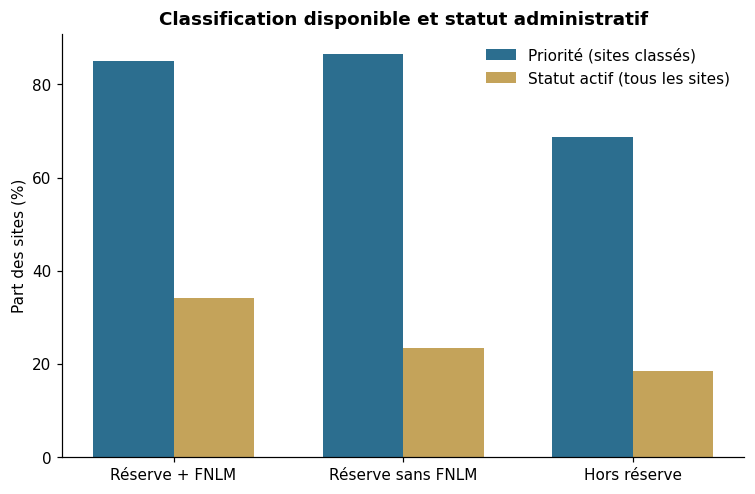

In [23]:
filtres_categories = filtres_groupes(echantillon_final)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.grid": False})

# --- Figure 4.1 : priorite et statut actif

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(3)
largeur = 0.35
ax.bar(x - largeur / 2, stats_categories["priorite_action"] * 100, largeur,
       label="Priorité (sites classés)", color="#2C6E8F")
ax.bar(x + largeur / 2, stats_categories["statut_actif"] * 100, largeur,
       label="Statut actif (tous les sites)", color="#C4A35A")
ax.set_xticks(x, stats_categories["groupe"])
ax.set_ylabel("Part des sites (%)")
ax.set_title("Classification disponible et statut administratif")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)


## 2.2 Statut administratif des sites  *(rapport 4.1, figure 4.2)*

Les sites FNLM présentent la plus forte proportion de statuts actifs. Les sites hors réserve sont plus souvent fermés.

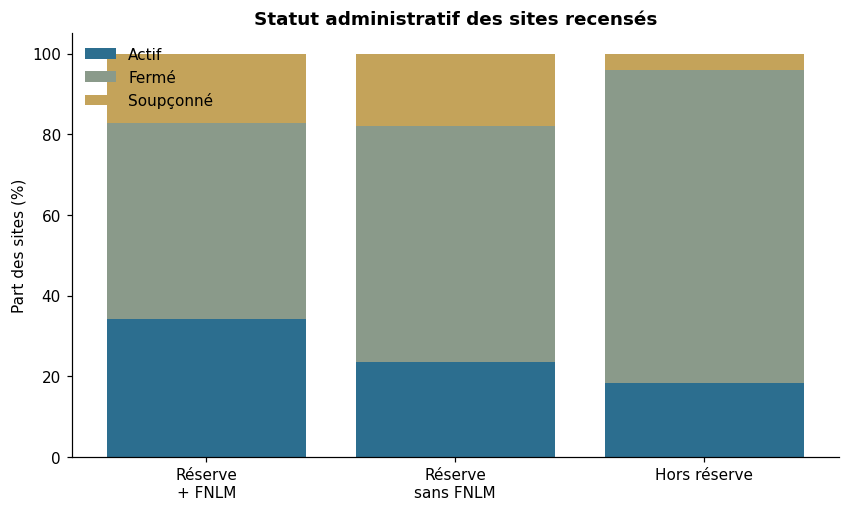

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
statuts = ["Active", "Closed", "Suspected"]
etiquettes = ["Actif", "Fermé", "Soupçonné"]
bas = np.zeros(3)
for statut, etiquette, couleur in zip(statuts, etiquettes, ["#2C6E8F", "#8A9A8A", "#C4A35A"]):
    valeurs = [echantillon_final.loc[masque, "sitestatus"].eq(statut).mean() * 100 for masque in filtres_categories.values()]
    ax.bar(np.arange(3), valeurs, bottom=bas, label=etiquette, color=couleur)
    bas += np.asarray(valeurs)

ax.set_xticks(
    np.arange(3), [nom.replace(" sans ", "\nsans ").replace(" + ", "\n+ ")
                   for nom in filtres_categories]
)
ax.set_ylabel("Part des sites (%)")
ax.set_title("Statut administratif des sites recensés")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)


## 2.3 Répartition provinciale  *(rapport 3.1.3, figure 3.1)*

La Colombie-Britannique regroupe 1 578 sites sur réserve, dont 643 associés à des Premières Nations FNLM. Elle devance la Saskatchewan (818 sites, dont 165 FNLM) et le Manitoba (744 sites, dont 216 FNLM).

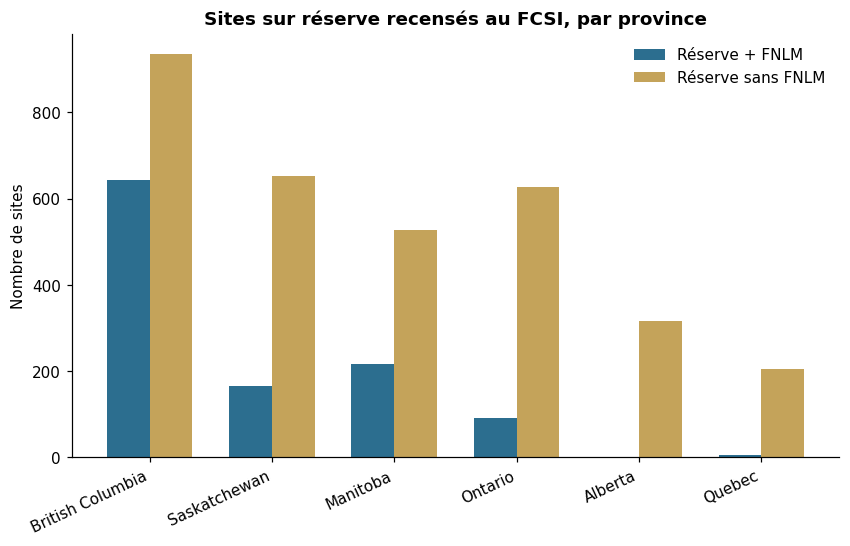

In [25]:
stats_provinces = (
    echantillon_final[echantillon_final["est_reserve"].eq(1)]
    .groupby("province")
    .agg(
        total=("federalsiteidentifier", "size"),
        sites_fnlm=("reserve_lma", "sum"),
        classes_valides=("classification_disponible", "sum"),
        couverture_classe=("classification_disponible", "mean"),
        priorite=("priorite_action", "mean"),
        actif=("statut_actif", "mean"),
    )
    .sort_values("total", ascending=False)
    .reset_index()
)
provinces_principales = stats_provinces.head(6).copy()
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(provinces_principales))
largeur = 0.35
ax.bar(x - largeur / 2, provinces_principales["sites_fnlm"], largeur, label="Réserve + FNLM", color="#2C6E8F")
ax.bar(x + largeur / 2, provinces_principales["total"] - provinces_principales["sites_fnlm"], largeur,
       label="Réserve sans FNLM", color="#C4A35A")
ax.set_xticks(x, provinces_principales["province"], rotation=25, ha="right")
ax.set_ylabel("Nombre de sites")
ax.set_title("Sites sur réserve recensés au FCSI, par province")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

## 2.4 Tableau provincial  *(rapport 3.1.3, tableau 3.1)*

Le tableau reprend les statistiques provinciales déjà calculées pour le graphique, ajoute par soustraction la colonne des sites sans FNLM, et renomme les colonnes pour l'affichage.

In [26]:
table_provinces_finale = stats_provinces.copy()

table_provinces_finale["non_fnlm"] = (table_provinces_finale["total"] - table_provinces_finale["sites_fnlm"])

table_provinces_finale = table_provinces_finale.rename(columns={
    "province": "Province", "total": "Total", "sites_fnlm": "FNLM",
    "non_fnlm": "Sans FNLM", "classes_valides": "Sites classés",
    "couverture_classe": "Couverture", "priorite": "Priorité", "actif": "Actif",
})

montrer_tableau(table_provinces_finale[["Province", "Total", "FNLM", "Sans FNLM", "Sites classés", "Couverture", "Priorité", "Actif",]],
    formats={
        "Total": "{:,}", "FNLM": "{:,}", "Sans FNLM": "{:,}", "Sites classés": "{:,}",
        "Couverture": "{:.1%}", "Priorité": "{:.1%}", "Actif": "{:.1%}",
    },
    titre="Sites sur réserve recensés au FCSI, par province",
)
print(f"Total sur réserve : {int(echantillon_final['est_reserve'].sum()):,} sites")

Total sur réserve : 4,503 sites


Province,Total,FNLM,Sans FNLM,Sites classés,Couverture,Priorité,Actif
British Columbia,"1,578",643,935,803,50.9%,85.1%,40.2%
Saskatchewan,818,165,653,153,18.7%,69.3%,12.6%
Manitoba,744,216,528,275,37.0%,89.1%,22.6%
Ontario,718,92,626,424,59.1%,87.7%,17.5%
Alberta,318,2,316,206,64.8%,92.2%,25.2%
Quebec,210,6,204,136,64.8%,91.9%,25.7%
Nova Scotia,42,3,39,1,2.4%,100.0%,7.1%
New Brunswick,38,3,35,6,15.8%,83.3%,10.5%
Northwest Territories,15,0,15,10,66.7%,70.0%,6.7%
Yukon,8,0,8,6,75.0%,100.0%,12.5%


## 2.5 Principales organisations déclarantes  *(rapport 2.4 et 4.8.8)*

Le regroupement par organisation compte les sites au total, sur réserve et FNLM, puis retient les dix premières. 

In [27]:
table_organisations = (
    echantillon_final.groupby("reportingorganization")
    .agg(
        Tous_les_sites=("federalsiteidentifier", "size"),
        Sites_sur_reserve=("est_reserve", "sum"),
        Sites_FNLM=("reserve_lma", "sum"),
    )
    .sort_values("Tous_les_sites", ascending=False)
    .head(10)
    .reset_index()
    .rename(columns={"reportingorganization": "Organisation déclarante"})
)
montrer_tableau(
    table_organisations,
    formats={"Tous_les_sites": "{:,}", "Sites_sur_reserve": "{:,}", "Sites_FNLM": "{:,}"},
    titre="Principales organisations déclarantes",
)

Organisation déclarante,Tous_les_sites,Sites_sur_reserve,Sites_FNLM
Fisheries and Oceans Canada,"11,013",2,0
Indigenous Services Canada,"4,418","4,340","1,131"
National Defence,"1,946",4,0
Environment and Climate Change Canada,"1,328",101,0
Crown-Indigenous Relations and Northern Affairs Canada,"1,004",0,0
Royal Canadian Mounted Police,999,0,0
Transport Canada,944,1,0
Agriculture and Agri-Food Canada,544,0,0
Parks Canada Agency,485,0,0
Public Services and Procurement Canada,481,1,0


# Partie 3 — Régressions principales

## 3.1 Outils d’estimation

Les modèles de probabilité linéaire comparent les deux catégories de réserves aux sites hors réserve. Les erreurs-types principales sont regroupées au niveau de la Première Nation pour les réserves et au niveau du site hors réserve.

**Modèle 1 : priorité d’action**


`choisir_controles` traduit un nom de spécification en liste de colonnes,
`lancer_lpm` assemble la matrice, retire les lignes incomplètes et ajuste le modèle avec erreurs-types regroupées, 
`tester_ecart_reserves` teste l'égalité des deux coefficients de réserve par la méthode delta, puis
`resume_lpm` met le résultat en dictionnaire. Les définir ici évite de répéter la même mécanique dans chaque test de robustesse.

In [28]:
def ajouter_etoiles(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

NOMS_INDICATEURS = {
    "priorite_action": "Priorité d'action",
    "statut_actif": "Statut actif",
    "haute_priorite_action": "Haute priorité",
}

def choisir_controles(donnees, specification):

    if isinstance(specification, list):
        return specification
    if specification == "aucun":
        return []
    if specification == "province":
        return [c for c in donnees.columns if c.startswith("prov_")]
    if specification == "province_organisation":
        return [c for c in donnees.columns if c.startswith(("prov_", "org_"))]
    raise ValueError(f"Spécification inconnue : {specification}")

def lancer_lpm(donnees, y, specification, type_erreurs="cluster", poids_nations=None):

    variables_explicatives = ["reserve_lma", "reserve_non_lma"] + choisir_controles(
        donnees, specification
    )
    colonnes_modele = [y, "grappe"] + variables_explicatives
    d = donnees[colonnes_modele].copy()
    if poids_nations is not None:
        d["_poids"] = poids_nations.reindex(d.index)
    d = d.dropna()
    X = sm.add_constant(d[variables_explicatives].astype(float), has_constant="add")
    yv = d[y].astype(float)
    ajustement = (sm.OLS(yv, X) if poids_nations is None
                  else sm.WLS(yv, X, weights=d["_poids"].astype(float)))
    if type_erreurs == "cluster":
        return ajustement.fit(
            cov_type="cluster",
            cov_kwds={"groups": d["grappe"], "use_correction": True},
        )
    if type_erreurs == "HC1":
        return ajustement.fit(cov_type="HC1")
    raise ValueError(f"Covariance inconnue : {type_erreurs}")

def tester_ecart_reserves(modele):
    """Ecart entre les deux categories de reserves, son erreur-type et sa valeur p."""
    difference = modele.params["reserve_lma"] - modele.params["reserve_non_lma"]
    cov = modele.cov_params()
    variance = (cov.loc["reserve_lma", "reserve_lma"]
                + cov.loc["reserve_non_lma", "reserve_non_lma"]
                - 2 * cov.loc["reserve_lma", "reserve_non_lma"])
    erreur = float(np.sqrt(max(float(variance), 0.0)))
    valeur_p = float(
        modele.wald_test("reserve_lma = reserve_non_lma", use_f=False, scalar=True).pvalue
    )
    return float(difference), erreur, valeur_p

def resume_lpm(modele, indicateur_etudie):

    difference, erreur_difference, p_difference = tester_ecart_reserves(modele)
    resume = {
        "issue": indicateur_etudie,
        "b_fnlm": modele.params["reserve_lma"],
        "se_fnlm": modele.bse["reserve_lma"],
        "p_fnlm": modele.pvalues["reserve_lma"],
        "b_non_fnlm": modele.params["reserve_non_lma"],
        "se_non_fnlm": modele.bse["reserve_non_lma"],
        "p_non_fnlm": modele.pvalues["reserve_non_lma"],
        "difference": difference,
        "se_difference": erreur_difference,
        "p_difference": p_difference,
    }
    resume["N"] = int(modele.nobs)
    return resume

def montrer_resultats_lpm(sorties_regression, indicateur_etudie, titre):

    table = sorties_regression[sorties_regression["issue"].eq(indicateur_etudie)].copy()
    table["Spécification"] = table["specification"].map({
        "aucun": "Sans contrôles",
        "province": "Effets fixes provinciaux",
    })
    for colonne, prefixe in [("Réserve + FNLM", "fnlm"), ("Réserve sans FNLM", "non_fnlm")]:
        b, se, p = f"b_{prefixe}", f"se_{prefixe}_cluster", f"p_{prefixe}_cluster"
        table[colonne] = table.apply(
            lambda r, b=b, se=se, p=p: f'{r[b]:.4f}{ajouter_etoiles(r[p])} ({r[se]:.4f})', axis=1
        )
    table["Écart FNLM − sans FNLM"] = table.apply(
        lambda r: f'{r["difference"]:.4f} ({r["se_difference"]:.4f})', axis=1
    )
    table["N"] = table["N"].astype(int)
    table = table.rename(columns={"p_difference": "p(égalité)", "r2": "R²"})
    montrer_tableau(
        table[[
            "Spécification", "Réserve + FNLM", "Réserve sans FNLM",
            "Écart FNLM − sans FNLM", "p(égalité)", "R²", "N",
        ]],
        formats={"p(égalité)": "{:.4f}", "R²": "{:.4f}", "N": "{:,}"},
        titre=titre,
    )

def creer_poids_nations(donnees, y):
    """Poids donnant le meme total a chaque Premiere Nation, quel que soit
    le nombre de sites qu'elle compte."""
    filtre_observe = donnees[y].notna()
    tailles = donnees.loc[filtre_observe].groupby("grappe")[y].transform("size")
    poids_nations = pd.Series(np.nan, index=donnees.index, dtype=float)
    poids_nations.loc[filtre_observe] = 1.0 / tailles.astype(float)
    return poids_nations

def montrer_robustesse(table, titre):
    """Mise en forme commune aux tableaux de robustesse LPM."""
    affiche = table.rename(columns={
        "issue": "Issue",
        "b_fnlm": "FNLM",
        "se_fnlm": "ET FNLM",
        "b_non_fnlm": "Sans FNLM",
        "se_non_fnlm": "ET sans FNLM",
        "difference": "Différence",
        "p_difference": "p(égalité)",
        "N": "N",
    })
    montrer_tableau(
        affiche[["Issue", "FNLM", "ET FNLM", "Sans FNLM", "ET sans FNLM",
                 "Différence", "p(égalité)", "N"]],
        formats={
            "FNLM": "{:.4f}", "ET FNLM": "{:.4f}",
            "Sans FNLM": "{:.4f}", "ET sans FNLM": "{:.4f}",
            "Différence": "{:.4f}", "p(égalité)": "{:.4f}", "N": "{:,}",
        },
        titre=titre,
    )

def lpm_sur_reserve_etendu(donnees, y, supplements=None, poids=False):
    """Equation (2) du rapport, avec controles et ponderation facultatifs."""
    d = donnees[donnees["est_reserve"].eq(1)].copy()
    provinces = pd.get_dummies(d["province"], prefix="prov_res",
                               drop_first=True, dtype=float)
    d = pd.concat([d, provinces], axis=1)
    colonnes = ["reserve_lma"] + list(provinces.columns)

    if supplements == "organisation":
        organisations = pd.get_dummies(d["reportingorganization"], prefix="org_res",
                                       drop_first=True, dtype=float)
        d = pd.concat([d, organisations], axis=1)
        colonnes += list(organisations.columns)
    elif supplements:
        colonnes += list(supplements)

    d = d[[y, "grappe"] + colonnes].dropna()
    X = sm.add_constant(d[colonnes].astype(float), has_constant="add")
    yv = d[y].astype(float)

    if poids:
        # Meme poids total a chaque Premiere Nation, calcule sur le sous-echantillon.
        tailles = d.groupby("grappe")[y].transform("size").astype(float)
        ajustement = sm.WLS(yv, X, weights=1.0 / tailles)
    else:
        ajustement = sm.OLS(yv, X)

    modele = ajustement.fit(cov_type="cluster",
                            cov_kwds={"groups": d["grappe"], "use_correction": True})
    return modele, d

## 3.2 Estimation des trois modèles  *(rapport 4.2, tableau 4.2)*

La double boucle croise les trois issues et les deux spécifications (sans contrôles, puis effets fixes provinciaux). Chaque modèle est ajusté deux fois, avec erreurs-types regroupées puis HC1, afin de comparer les deux plus bas ; les coefficients, eux, sont identiques. Les résultats sont empilés dans un tableau unique, réutilisé par les trois cellules d'affichage.


In [29]:
indicateurs_modeles = list(NOMS_INDICATEURS)
liste_modeles = []
modeles_finaux = {}
for y in indicateurs_modeles:
    for specification in ["aucun", "province"]:
        modele = lancer_lpm(echantillon_final, y, specification, type_erreurs="cluster")
        regression_hc1 = lancer_lpm(echantillon_final, y, specification, type_erreurs="HC1")
        difference, erreur_difference, p_difference = tester_ecart_reserves(modele)
        cle = f"{y}_{specification}"
        modeles_finaux[cle] = modele
        liste_modeles.append(
            {
                "issue": y,
                "specification": specification,
                "b_fnlm": modele.params["reserve_lma"],
                "se_fnlm_cluster": modele.bse["reserve_lma"],
                "p_fnlm_cluster": modele.pvalues["reserve_lma"],
                "se_fnlm_hc1": regression_hc1.bse["reserve_lma"],
                "b_non_fnlm": modele.params["reserve_non_lma"],
                "se_non_fnlm_cluster": modele.bse["reserve_non_lma"],
                "p_non_fnlm_cluster": modele.pvalues["reserve_non_lma"],
                "se_non_fnlm_hc1": regression_hc1.bse["reserve_non_lma"],
                "difference": difference,
                "se_difference": erreur_difference,
                "p_difference": p_difference,
                "r2": modele.rsquared,
                "N": int(modele.nobs),
            }
        )
table_resultats_lpm = pd.DataFrame(liste_modeles)

montrer_resultats_lpm(table_resultats_lpm, "priorite_action", "Modèle 1 — priorité d'action")

Spécification,Réserve + FNLM,Réserve sans FNLM,Écart FNLM − sans FNLM,p(égalité),R²,N
Sans contrôles,0.1628*** (0.0243),0.1789*** (0.0124),-0.0161 (0.0263),0.5408,0.0235,"10,621"
Effets fixes provinciaux,0.1248*** (0.0261),0.1449*** (0.0137),-0.0201 (0.0270),0.4576,0.0394,"10,621"


## 3.3 Modèle 2 — statut actif  *(rapport 4.3.2)*

Avec effets fixes provinciaux, la probabilité qu'un site soit actif est supérieure de 19,3 points de pourcentage pour les sites FNLM et de 8,1 points pour les réserves non-FNLM, par rapport aux sites hors réserve. L'écart de 11,2 points entre les deux catégories de réserves est statistiquement significatif (`p < 0,001`), mais demeure associatif.

**Modèle 2 : statut de site actif**

L'estimation a déjà eu lieu dans la cellule des modèles principaux. Cette ligne extrait du tableau de résultats les lignes du statut actif et les met en forme.

In [30]:
montrer_resultats_lpm(table_resultats_lpm, "statut_actif", "Modèle 2 — statut actif")

Spécification,Réserve + FNLM,Réserve sans FNLM,Écart FNLM − sans FNLM,p(égalité),R²,N
Sans contrôles,0.1574*** (0.0319),0.0502*** (0.0139),0.1072 (0.0345),0.0019,0.0083,"23,801"
Effets fixes provinciaux,0.1928*** (0.0289),0.0807*** (0.0130),0.1121 (0.0313),0.0003,0.0385,"23,801"


## 3.4 Modèle 3 — haute priorité  *(rapport 4.3.2 et 4.3.3)*

**Modèle 3 : haute priorité : vérification de robustesse**

Cette issue vaut 1 seulement pour `High Priority for Action` et reste manquante lorsque la classification n'est pas informative.

Même mécanisme que pour les deux modèles précédents : les résultats sont déjà calculés, seule la mise en forme change.


### Interprétation
Avec effets fixes provinciaux, le coefficient FNLM est de 0,4 point de pourcentage et n'est pas distinguable de zéro, alors que celui des réserves non-FNLM atteint 15,3 points. L'écart de −14,9 points entre les deux catégories de réserves est très significatif (p = 0,0001).

Les trois issues ne racontent pas la même histoire. Pour la priorité d'action, les deux catégories de réserves sont indistinguables (écart de −2,0 points, p = 0,458). Pour le statut actif, les sites FNLM sont nettement plus souvent actifs (+11,2 points, p < 0,001). Pour la haute priorité, ils le sont nettement moins (−14,9 points).

Le R² des six modèles du tableau va de 0,008 à 0,084 : le statut FNLM, la province et le fait d'être sur réserve expliquent moins de 10 % de la variation des issues. Ces coefficients sont des écarts conditionnels de probabilité, pas des effets causaux du régime FNLM.

In [31]:
montrer_resultats_lpm(table_resultats_lpm, "haute_priorite_action", "Modèle 3 — haute priorité")

Spécification,Réserve + FNLM,Réserve sans FNLM,Écart FNLM − sans FNLM,p(égalité),R²,N
Sans contrôles,0.1000*** (0.0319),0.2070*** (0.0190),-0.1070 (0.0368),0.0036,0.0403,"10,621"
Effets fixes provinciaux,0.0042 (0.0320),0.1529*** (0.0209),-0.1487 (0.0367),0.0001,0.0840,"10,621"


## 3.5 Équation (2) — sites sur réserve seulement  *(rapport 4.3.4, tableau 4.4 ; le graphique de coefficients produit ici est la figure 4.3, placée en 4.2 du rapport)*

Un panneau par issue, partageant le même axe vertical. `errorbar` trace le coefficient et son intervalle à 95 %, obtenu en multipliant l'erreur-type regroupée par 1,96. La ligne verticale à zéro sert de repère : un intervalle qui la croise signale un écart non significatif.

**Modèle restreint aux seuls sites sur réserve**

La question de recherche porte sur les sites situés sur une réserve, mais les trois modèles
précédents gardent les sites hors réserve comme catégorie omise et ne récupèrent le contraste
qui nous intéresse qu'indirectement, par un test de Wald sur `β₁ − β₂`. Ce n'est pas équivalent
à une estimation directe : dans le modèle groupé, les effets fixes provinciaux sont estimés à
plus de 80 % sur des sites hors réserve, donc calibrés sur une variation qui n'est pas celle
des réserves entre elles.

Le modèle ci-dessous ne voit que les 4 503 sites sur réserve. Les indicatrices provinciales y
sont reconstruites sur ce seul sous-échantillon, ce qui est nécessaire : une province sans site
sur réserve donnerait une colonne nulle, et `reserve_non_lma` y étant le complément exact de
`reserve_lma`, la matrice du modèle groupé y serait singulière.

y = α + δ·FNLM + effets fixes provinciaux + ε




### Interprétation des résultats

Après contrôle provincial dans l'échantillon restreint aux sites sur réserve, l'écart entre les sites FNLM et les autres réserves est de +0,5 point pour la priorité d'action (`p = 0,837`), de +5,3 points pour le statut actif (`p = 0,056`) et de −10,1 points pour la haute priorité (`p = 0,008`). Seul l'écart de haute priorité est statistiquement significatif au seuil de 5 %, tandis que celui du statut actif demeure suggestif. Les intervalles illustrent l'incertitude calculée avec regroupement au niveau de la Première Nation.



A reporter en 4.3.4 : estime sur les seuls sites sur reserve, l'ecart entre les reserves FNLM et les autres est de +0.5 point(s) pour la priorite d'action (p = 0.837), de +5.3 pour le statut actif (p = 0.056) et de -10.1 pour la haute priorite (p = 0.008). Les ecarts avec la difference b1 - b2 du Tableau 4.3 valent respectivement +2.5, -6.0 et +4.8 point(s).
Grappes mobilisees : 553 pour les issues de classification, 692 pour le statut actif.
Out[1]: Text(0.5, 0.98, 'Coefficients LPM et intervalles de confiance à 95 %')


Issue,δ (sur réserve),ET,Valeur p,β₁ − β₂ (modèle groupé),Écart entre les deux,N,Grappes
Priorité d'action,0.0053,0.0260,0.8374,-0.0201,+0.0254,"2,027",553
Statut actif,0.0526,0.0275,0.0561,0.1121,-0.0596,"4,503",692
Haute priorité,-0.1006,0.0377,0.0076,-0.1487,+0.0481,"2,027",553


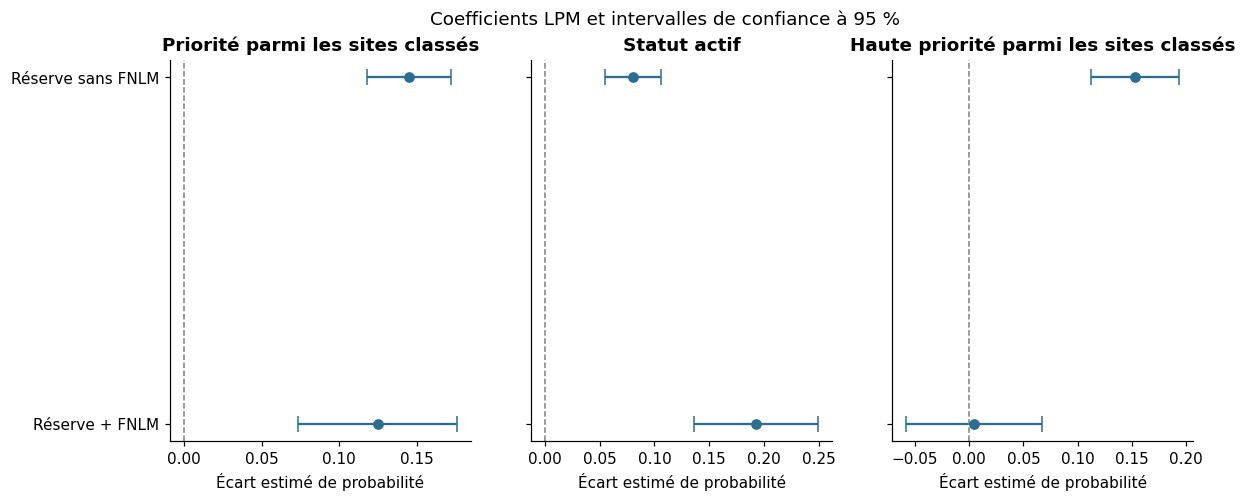

In [32]:
lignes_sur_reserve = []
for y in indicateurs_modeles:
    modele_res, donnees_res = lpm_sur_reserve_etendu(echantillon_final, y)
    # meme quantite, recuperee indirectement par le modele groupe
    ligne = table_resultats_lpm[
        table_resultats_lpm["issue"].eq(y) & table_resultats_lpm["specification"].eq("province")
    ].iloc[0]
    lignes_sur_reserve.append({
        "cle": y,
        "issue": NOMS_INDICATEURS[y],
        "delta": modele_res.params["reserve_lma"],
        "erreur_type": modele_res.bse["reserve_lma"],
        "valeur_p": modele_res.pvalues["reserve_lma"],
        "ecart_groupe": ligne["difference"],
        "difference": modele_res.params["reserve_lma"] - ligne["difference"],
        "N": int(modele_res.nobs),
        "grappes": donnees_res["grappe"].nunique(),
    })

table_sur_reserve = pd.DataFrame(lignes_sur_reserve)

montrer_tableau(
    table_sur_reserve.drop(columns=["cle"]).rename(columns={
        "issue": "Issue", "delta": "δ (sur réserve)", "erreur_type": "ET",
        "valeur_p": "Valeur p", "ecart_groupe": "β₁ − β₂ (modèle groupé)",
        "difference": "Écart entre les deux", "N": "N", "grappes": "Grappes",
    }),
    formats={"δ (sur réserve)": "{:.4f}", "ET": "{:.4f}", "Valeur p": "{:.4f}",
             "β₁ − β₂ (modèle groupé)": "{:.4f}", "Écart entre les deux": "{:+.4f}",
             "N": "{:,}", "Grappes": "{:,}"},
    titre="Écart FNLM estimé sur les seuls sites sur réserve",
)

# Phrase prete a reporter dans le rapport, indexee par la cle d'issue et non par
# le libelle francais, dont l'apostrophe compliquerait inutilement le formatage.
resultats = {x["cle"]: x for x in lignes_sur_reserve}
pri, act, hau = (resultats["priorite_action"], resultats["statut_actif"],
                 resultats["haute_priorite_action"])
print(
    "\nA reporter en 4.3.4 : estime sur les seuls sites sur reserve, l'ecart entre les "
    f"reserves FNLM et les autres est de {100 * pri['delta']:+.1f} point(s) pour la priorite "
    f"d'action (p = {pri['valeur_p']:.3f}), de {100 * act['delta']:+.1f} pour le statut actif "
    f"(p = {act['valeur_p']:.3f}) et de {100 * hau['delta']:+.1f} pour la haute priorite "
    f"(p = {hau['valeur_p']:.3f}). Les ecarts avec la difference b1 - b2 du Tableau 4.3 valent "
    f"respectivement {100 * pri['difference']:+.1f}, {100 * act['difference']:+.1f} et "
    f"{100 * hau['difference']:+.1f} point(s)."
)
print(f"Grappes mobilisees : {pri['grappes']:,} pour les issues de classification, "
      f"{act['grappes']:,} pour le statut actif.")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharey=True)
for ax, (cle, titre) in zip(
    axes,
    [
        ("priorite_action_province", "Priorité parmi les sites classés"),
        ("statut_actif_province", "Statut actif"),
        ("haute_priorite_action_province", "Haute priorité parmi les sites classés"),
    ],
):
    regression_graphique = modeles_finaux[cle]
    variables_explicatives = ["reserve_lma", "reserve_non_lma"]
    coefs = [regression_graphique.params[v] for v in variables_explicatives]
    erreurs = [1.96 * regression_graphique.bse[v] for v in variables_explicatives]
    positions = np.arange(2)
    ax.errorbar(coefs, positions, xerr=erreurs, fmt="o", color="#2C6E8F", capsize=5)
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_yticks(positions, ["Réserve + FNLM", "Réserve sans FNLM"])
    ax.set_xlabel("Écart estimé de probabilité")
    ax.set_title(titre)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Coefficients LPM et intervalles de confiance à 95 %")


# Partie 4 — Analyses de robustesse

## 4.1 Sensibilité au choix des erreurs-types  *(rapport 4.8.2, tableau 4.9)*

Les cellules suivantes reprennent les tableaux complémentaires du rapport avec les mêmes dénominateurs corrigés.
Le rapport entre l'erreur-type regroupée et l'erreur-type HC1 mesure l'ampleur de la corrélation intra-Nation : au-dessus de 1, ne pas regrouper sous-estimerait l'incertitude.


### Interprétation des résultats

Les coefficients sont identiques d'une colonne à l'autre ; seules les erreurs-types changent. Avec effets fixes provinciaux, le rapport entre erreur-type regroupée et erreur-type HC1 vaut 1,39 pour la priorité d'action, 1,99 pour le statut actif et 1,51 pour la haute priorité. Sans contrôles, les trois rapports sont un peu plus élevés, soit 1,42, 2,22 et 1,63.

Un rapport de 1,99 signifie que ne pas regrouper les erreurs-types au niveau de la Première Nation les diviserait par deux, et gonflerait d'autant les statistiques de test. Les sites d'une même Nation partagent une gouvernance, un déclarant et souvent un historique commun : les traiter comme des observations indépendantes surestime la quantité d'information disponible. C'est le regroupement qui est retenu pour toute l'interprétation.

In [33]:
table_ecarts_types = table_resultats_lpm.copy()
table_ecarts_types["Issue"] = table_ecarts_types["issue"].map(NOMS_INDICATEURS)
table_ecarts_types["Spécification"] = table_ecarts_types["specification"].map({
    "aucun": "Sans contrôles",
    "province": "Effets fixes provinciaux",
})
table_ecarts_types["Ratio"] = (
    table_ecarts_types["se_fnlm_cluster"] / table_ecarts_types["se_fnlm_hc1"]
)
table_ecarts_types = table_ecarts_types.rename(columns={
    "b_fnlm": "Coefficient FNLM",
    "se_fnlm_cluster": "ET regroupée",
    "se_fnlm_hc1": "ET HC1",
    "b_non_fnlm": "Coefficient sans FNLM",
    "se_non_fnlm_cluster": "ET regroupée (sans FNLM)",
    "se_non_fnlm_hc1": "ET HC1 (sans FNLM)",
})
montrer_tableau(
    table_ecarts_types[[
        "Issue", "Spécification", "Coefficient FNLM", "ET regroupée", "ET HC1", "Ratio",
        "Coefficient sans FNLM", "ET regroupée (sans FNLM)", "ET HC1 (sans FNLM)",
    ]],
    formats={
        "Coefficient FNLM": "{:.4f}", "ET regroupée": "{:.4f}", "ET HC1": "{:.4f}",
        "Ratio": "{:.2f}", "Coefficient sans FNLM": "{:.4f}",
        "ET regroupée (sans FNLM)": "{:.4f}", "ET HC1 (sans FNLM)": "{:.4f}",
    },
    titre="Erreurs-types regroupées et HC1 — coefficients identiques",
)

Issue,Spécification,Coefficient FNLM,ET regroupée,ET HC1,Ratio,Coefficient sans FNLM,ET regroupée (sans FNLM),ET HC1 (sans FNLM)
Priorité d'action,Sans contrôles,0.1628,0.0243,0.0171,1.42,0.1789,0.0124,0.0100
Priorité d'action,Effets fixes provinciaux,0.1248,0.0261,0.0188,1.39,0.1449,0.0137,0.0113
Statut actif,Sans contrôles,0.1574,0.0319,0.0144,2.22,0.0502,0.0139,0.0078
Statut actif,Effets fixes provinciaux,0.1928,0.0289,0.0145,1.99,0.0807,0.0130,0.0082
Haute priorité,Sans contrôles,0.1000,0.0319,0.0196,1.63,0.2070,0.0190,0.0125
Haute priorité,Effets fixes provinciaux,0.0042,0.0320,0.0211,1.51,0.1529,0.0209,0.0134


## 4.2 Sous-échantillon de la Colombie-Britannique  *(rapport 4.4, tableau 4.5)*

Le même appareil est réappliqué au seul sous-échantillon de la Colombie-Britannique, qui concentre le plus de sites sur réserve. `lancer_lpm` est appelée sans contrôles : la province étant désormais constante, des effets fixes provinciaux n'auraient plus aucune variation à absorber.



### Interprétation des résultats

La Colombie-Britannique concentre 1 578 sites sur réserve, dont 643 FNLM. Restreint à cette seule province, l'écart de statut actif entre sites FNLM et autres réserves reste de +11,7 points et significatif (p = 0,005), très proche des +11,2 points obtenus sur l'échantillon complet.

La concordance des deux estimations indique que le résultat principal ne tient pas à la composition provinciale de l'échantillon. Pour la haute priorité, l'écart s'atténue (−9,3 points, p = 0,090) et pour la priorité d'action il change même de signe sans être significatif : ces deux résultats-là sont moins stables géographiquement.

In [34]:


echantillon_cb = echantillon_final[echantillon_final["province"].eq("British Columbia")].copy()
table_resultats_cb = pd.DataFrame([
    resume_lpm(lancer_lpm(echantillon_cb, y, "aucun"), y)
    for y in indicateurs_modeles
])


montrer_tableau(
    table_resultats_cb.rename(columns={
        "issue": "Issue", "b_fnlm": "Coefficient FNLM", "se_fnlm": "ET FNLM",
        "b_non_fnlm": "Coefficient sans FNLM", "se_non_fnlm": "ET sans FNLM",
        "difference": "Différence", "p_difference": "p(égalité)", "N": "N",
    })[[
        "Issue", "Coefficient FNLM", "ET FNLM", "Coefficient sans FNLM",
        "ET sans FNLM", "Différence", "p(égalité)", "N",
    ]],
    formats={
        "Coefficient FNLM": "{:.4f}", "ET FNLM": "{:.4f}",
        "Coefficient sans FNLM": "{:.4f}", "ET sans FNLM": "{:.4f}",
        "Différence": "{:.4f}", "p(égalité)": "{:.4f}", "N": "{:,}",
    },
    titre="Robustesse — sous-échantillon de la Colombie-Britannique",
)

Issue,Coefficient FNLM,ET FNLM,Coefficient sans FNLM,ET sans FNLM,Différence,p(égalité),N
priorite_action,0.1062,0.0266,0.0873,0.0249,0.0189,0.5425,"1,824"
statut_actif,0.3467,0.0358,0.2294,0.0237,0.1172,0.0054,"4,781"
haute_priorite_action,-0.0403,0.0447,0.0530,0.0380,-0.0933,0.0897,"1,824"


## 4.3 Dépenses de remédiation et d’évaluation  *(rapport 4.5 et 4.5.1, tableau 4.6)*

La cellule agrège les dépenses par site : les quatre postes sont sommés sur tous les exercices observés, et le nombre d'exercices renseignés est conservé pour ramener les montants à une base annuelle. Elle calcule ensuite, pour chaque catégorie, la moyenne cumulée, la moyenne par exercice observé, la médiane, la part de sites ayant enregistré au moins une dépense positive et la médiane parmi ces derniers.



### Interprétation des résultats

La dépense moyenne de remédiation cumulée atteint 75 513 $ par site  FNLM, contre 144 287$ sur les autres réserves et 282 237 $ hors réserve. La part de sites ayant enregistré au moins une dépense de remédiation suit le même ordre : 11,5 %, 20,4 % et 17,2 %.

Cet écart ne mesure pas un sous-financement. Les montants déclarés dépendent de l'avancement du dossier, du régime de propriété et des pratiques de déclaration de l'organisation responsable. Un site peu avancé dans le processus d'évaluation affiche mécaniquement des dépenses faibles.

Le classement s'inverse partiellement : la médiane de remédiation parmi les sites qui dépensent est de 101 324 $ pour les sites FNLM, contre 69 236 $ et 43 747 $. Autrement dit, moins de sites FNLM engagent des dépenses, mais ceux qui le font engagent des montants plus élevés.

In [35]:
DEPENSES_ANALYSEES = ["totalremediationexpenditure", "totalassessmentexpenditure"]

depenses_par_annee = panel_fcsi_complet.copy()
depenses_par_annee[COLONNES_DEPENSES] = (
    depenses_par_annee[COLONNES_DEPENSES].apply(pd.to_numeric, errors="coerce").astype(float)
)

# Cumul des depenses et nombre d'exercices observes, par site.
par_site = depenses_par_annee.groupby("federalsiteidentifier")
depenses_par_site = (
    par_site[COLONNES_DEPENSES].sum(min_count=1)
    .join(par_site["fiscalyear"].nunique().rename("exercices_observes"))
    .reset_index()
)
base_depenses = echantillon_final[
    ["federalsiteidentifier", "reserve_lma", "reserve_non_lma", "est_reserve"]
].merge(depenses_par_site, on="federalsiteidentifier", how="left")

liste_depenses = []
for libelle, masque in filtres_groupes(base_depenses).items():
    exercices = base_depenses.loc[masque, "exercices_observes"]
    for variable in DEPENSES_ANALYSEES:
        x = base_depenses.loc[masque, variable]
        x_observe = x.dropna()
        liste_depenses.append({
            "groupe": libelle,
            "variable": variable,
            "moyenne_cumulative_nominale": x.mean(),
            "moyenne_par_exercice_observe": (x / exercices).mean(),
            "mediane_cumulative": x.median(),
            "part_positive": x_observe.gt(0).mean(),
            "mediane_si_positive": x_observe[x_observe > 0].median(),
            "N_non_manquant": int(x.notna().sum()),
            "exercices_moyens": exercices.mean(),
        })
table_depenses = pd.DataFrame(liste_depenses)


montrer_tableau(
    table_depenses.replace({"totalremediationexpenditure": "Remédiation",
                            "totalassessmentexpenditure": "Évaluation"}).rename(columns={
        "groupe": "Catégorie", "variable": "Dépense",
        "moyenne_cumulative_nominale": "Somme moyenne observée",
        "moyenne_par_exercice_observe": "Moyenne par exercice",
        "mediane_cumulative": "Médiane observée", "part_positive": "Part positive",
        "mediane_si_positive": "Médiane si positive", "N_non_manquant": "N",
        "exercices_moyens": "Exercices moyens",
    }),
    formats={
        "Somme moyenne observée": "${:,.0f}", "Moyenne par exercice": "${:,.0f}",
        "Médiane observée": "${:,.0f}", "Part positive": "{:.1%}",
        "Médiane si positive": "${:,.0f}", "N": "{:,}", "Exercices moyens": "{:.1f}",
    },
    titre="Dépenses annuelles observées, agrégées par site",
)

Catégorie,Dépense,Somme moyenne observée,Moyenne par exercice,Médiane observée,Part positive,Médiane si positive,N,Exercices moyens
Réserve + FNLM,Remédiation,"$75,513","$8,843",$0,11.5%,"$101,324","1,132",8.6
Réserve + FNLM,Évaluation,"$12,758","$1,644",$0,41.3%,"$12,853","1,132",8.6
Réserve sans FNLM,Remédiation,"$144,287","$14,308",$0,20.4%,"$69,236","3,371",9.4
Réserve sans FNLM,Évaluation,"$16,476","$1,956",$0,49.8%,"$6,189","3,371",9.4
Hors réserve,Remédiation,"$282,237","$19,689",$0,17.2%,"$43,747","19,243",8.0
Hors réserve,Évaluation,"$21,083","$2,561","$1,106",52.4%,"$10,000","19,243",8.0


## 4.4 Dépenses en dollars constants  *(rapport 4.5)*

Le Tableau 4.6 est en dollars courants sur une trentaine d'exercices. La cellule reprend
exactement les définitions de la cellule des dépenses et n'ajoute que la déflation, par l'indice
des prix à la consommation d'ensemble du Canada (Statistique Canada, tableau 18-10-0005-01,
2002 = 100). Chaque exercice est rattaché à son année civile de début : l'exercice 2011-2012
prend l'indice de 2011.

La cellule imprime aussi l'année moyenne des dépenses de chaque catégorie, pondérée par les
montants. C'est elle qui décide si la déflation peut changer une comparaison : si les trois
catégories dépensent aux mêmes exercices, le déflateur leur applique un facteur voisin et
l'ordre est préservé.


In [36]:
# IPC d'ensemble, Canada, moyenne annuelle, 2002 = 100.
# Statistique Canada, tableau 18-10-0005-01.
IPC_CANADA = {
    1993: 85.6, 1994: 85.7, 1995: 87.6, 1996: 88.9, 1997: 90.4, 1998: 91.3,
    1999: 92.9, 2000: 95.4, 2001: 97.8, 2002: 100.0, 2003: 102.8, 2004: 104.7,
    2005: 107.0, 2006: 109.1, 2007: 111.5, 2008: 114.1, 2009: 114.4, 2010: 116.5,
    2011: 119.9, 2012: 121.7, 2013: 122.8, 2014: 125.2, 2015: 126.6, 2016: 128.4,
    2017: 130.4, 2018: 133.4, 2019: 136.0, 2020: 136.9, 2021: 141.6, 2022: 151.2,
    2023: 157.1,
}
ANNEE_BASE_DOLLARS = 2022

# Reprend le panel déjà converti en numérique à la section 4.3, pour que les deux
# sections partent par construction des mêmes définitions de dépenses.
panel_reel = depenses_par_annee.copy()
panel_reel["ipc"] = panel_reel["annee_debut"].map(IPC_CANADA)
if panel_reel["ipc"].isna().any():
    exercices = sorted(panel_reel.loc[panel_reel["ipc"].isna(), "annee_debut"].unique())
    raise ValueError(f"Exercices sans indice des prix : {exercices}")

facteur_reel = IPC_CANADA[ANNEE_BASE_DOLLARS] / panel_reel["ipc"]
COLONNES_DEPENSES_REELLES = [c + "_reel" for c in COLONNES_DEPENSES]
for nominale, reelle in zip(COLONNES_DEPENSES, COLONNES_DEPENSES_REELLES):
    panel_reel[reelle] = panel_reel[nominale] * facteur_reel

par_site_reel = panel_reel.groupby("federalsiteidentifier")
depenses_site_reel = (
    par_site_reel[COLONNES_DEPENSES + COLONNES_DEPENSES_REELLES].sum(min_count=1)
    .join(par_site_reel["fiscalyear"].nunique().rename("exercices_observes"))
    .reset_index()
)
base_depenses_reel = echantillon_final[
    ["federalsiteidentifier", "reserve_lma", "reserve_non_lma", "est_reserve"]
].merge(depenses_site_reel, on="federalsiteidentifier", how="left")

lignes_reelles = []
for libelle, masque in filtres_groupes(base_depenses_reel).items():
    exercices = base_depenses_reel.loc[masque, "exercices_observes"]
    for variable in DEPENSES_ANALYSEES:
        for suffixe, unite in [("", "courants"), ("_reel", f"constants {ANNEE_BASE_DOLLARS}")]:
            x = base_depenses_reel.loc[masque, variable + suffixe]
            lignes_reelles.append({
                "Catégorie": libelle,
                "Dépense": "Remédiation" if "remediation" in variable else "Évaluation",
                "Dollars": unite,
                "Somme moyenne": x.mean(),
                "Moyenne par exercice": (x / exercices).mean(),
                "Médiane si positive": x[x > 0].median(),
            })
table_depenses_reelles = pd.DataFrame(lignes_reelles)
montrer_tableau(
    table_depenses_reelles,
    formats={"Somme moyenne": "${:,.0f}", "Moyenne par exercice": "${:,.0f}",
             "Médiane si positive": "${:,.0f}"},
    titre=f"Dépenses en dollars courants et en dollars constants de {ANNEE_BASE_DOLLARS}",
)

# Annee moyenne des depenses, ponderee par les montants : c'est elle qui dit si la
# deflation peut renverser une comparaison.
panel_categories = panel_reel.merge(
    echantillon_final[["federalsiteidentifier", "reserve_lma", "reserve_non_lma", "est_reserve"]],
    on="federalsiteidentifier", how="inner",
)
print()
for libelle, masque in filtres_groupes(panel_categories).items():
    d = panel_categories[masque]
    poids = d["totalremediationexpenditure"].fillna(0).clip(lower=0)
    # np.average divise par la somme des poids : une categorie sans depense de
    # remediation positive n'a pas d'annee moyenne definie.
    if float(poids.sum()) <= 0:
        print(f"{libelle:20s} aucune depense de remediation positive : "
              "annee moyenne des depenses indefinie")
        continue
    annee = np.average(d["annee_debut"], weights=poids)
    print(f"{libelle:20s} annee moyenne des depenses de remediation : {annee:.1f}")

remed = table_depenses_reelles[table_depenses_reelles["Dépense"].eq("Remédiation")]
resume = remed.pivot(index="Catégorie", columns="Dollars", values="Somme moyenne")
# Le classement est verifie et non affirme : c'est precisement l'objet de la
# cellule que les facteurs de deflation different d'une categorie a l'autre.
COLONNE_REELLE = f"constants {ANNEE_BASE_DOLLARS}"
ordre_courants = list(resume["courants"].sort_values(ascending=False).index)
ordre_reels = list(resume[COLONNE_REELLE].sort_values(ascending=False).index)
if ordre_courants == ordre_reels:
    verdict_ordre = f"L'ordre des {len(resume)} categories est inchange."
else:
    verdict_ordre = (
        f"L'ordre des categories change : {' > '.join(ordre_courants)} en dollars "
        f"courants contre {' > '.join(ordre_reels)} en dollars constants.")

print("\nA reporter en 4.5 : en dollars constants de "
      f"{ANNEE_BASE_DOLLARS}, la somme moyenne des depenses de remediation passe de "
      + ", de ".join(
          f"{resume.loc[c, 'courants']:,.0f} $ a {resume.loc[c, COLONNE_REELLE]:,.0f} $ "
          f"({c})" for c in resume.index)
      + f". {verdict_ordre}")

comparaison = resume.copy()
comparaison["Facteur implicite"] = comparaison[COLONNE_REELLE] / comparaison["courants"]
reference = "Réserve + FNLM"
comparaison["Rapport aux sites FNLM, courants"] = (
    comparaison["courants"] / comparaison.loc[reference, "courants"])
comparaison[f"Rapport aux sites FNLM, {COLONNE_REELLE}"] = (
    comparaison[COLONNE_REELLE] / comparaison.loc[reference, COLONNE_REELLE])

montrer_tableau(
    comparaison.reset_index(),
    formats={"courants": "${:,.0f}", COLONNE_REELLE: "${:,.0f}",
             "Facteur implicite": "{:.2f}",
             "Rapport aux sites FNLM, courants": "{:.2f}",
             f"Rapport aux sites FNLM, {COLONNE_REELLE}": "{:.2f}"},
    titre="Facteurs de deflation et rapports entre categories, depenses de remediation",
)
print("\nA reporter en 4.5 (facteurs) : "
      + ", ".join(f"{comparaison.loc[c, 'Facteur implicite']:.2f} pour {c}"
                  for c in comparaison.index)
      + ". Le rapport des autres reserves aux sites FNLM passe de "
      f"{comparaison.loc['Réserve sans FNLM', 'Rapport aux sites FNLM, courants']:.2f} a "
      f"{comparaison.loc['Réserve sans FNLM', f'Rapport aux sites FNLM, {COLONNE_REELLE}']:.2f}, "
      "celui des sites hors reserve de "
      f"{comparaison.loc['Hors réserve', 'Rapport aux sites FNLM, courants']:.2f} a "
      f"{comparaison.loc['Hors réserve', f'Rapport aux sites FNLM, {COLONNE_REELLE}']:.2f}.")


Réserve + FNLM       annee moyenne des depenses de remediation : 2015.2
Réserve sans FNLM    annee moyenne des depenses de remediation : 2013.5
Hors réserve         annee moyenne des depenses de remediation : 2015.3

A reporter en 4.5 : en dollars constants de 2022, la somme moyenne des depenses de remediation passe de 282,237 $ a 335,534 $ (Hors réserve), de 75,513 $ a 90,019 $ (Réserve + FNLM), de 144,287 $ a 176,814 $ (Réserve sans FNLM). L'ordre des 3 categories est inchange.

A reporter en 4.5 (facteurs) : 1.19 pour Hors réserve, 1.19 pour Réserve + FNLM, 1.23 pour Réserve sans FNLM. Le rapport des autres reserves aux sites FNLM passe de 1.91 a 1.96, celui des sites hors reserve de 3.74 a 3.73.


Catégorie,Dépense,Dollars,Somme moyenne,Moyenne par exercice,Médiane si positive
Réserve + FNLM,Remédiation,courants,"$75,513","$8,843","$101,324"
Réserve + FNLM,Remédiation,constants 2022,"$90,019","$10,776","$118,806"
Réserve + FNLM,Évaluation,courants,"$12,758","$1,644","$12,853"
Réserve + FNLM,Évaluation,constants 2022,"$15,743","$1,986","$15,603"
Réserve sans FNLM,Remédiation,courants,"$144,287","$14,308","$69,236"
Réserve sans FNLM,Remédiation,constants 2022,"$176,814","$18,017","$87,950"
Réserve sans FNLM,Évaluation,courants,"$16,476","$1,956","$6,189"
Réserve sans FNLM,Évaluation,constants 2022,"$20,607","$2,402","$8,322"
Hors réserve,Remédiation,courants,"$282,237","$19,689","$43,747"
Hors réserve,Remédiation,constants 2022,"$335,534","$23,456","$52,822"


Dollars,Catégorie,constants 2022,courants,Facteur implicite,"Rapport aux sites FNLM, courants","Rapport aux sites FNLM, constants 2022"
,Hors réserve,"$335,534","$282,237",1.19,3.74,3.73
,Réserve + FNLM,"$90,019","$75,513",1.19,1.00,1.00
,Réserve sans FNLM,"$176,814","$144,287",1.23,1.91,1.96


## 4.5 Nature des contaminants  *(rapport 4.6, tableau 4.7)*

Les trois familles de contaminants sont repérées par expression régulière dans le champ texte `mediumcontaminants`. Les catégories ne sont pas exclusives : un site peut compter dans plusieurs. Le dénominateur est restreint aux sites dont le champ est renseigné, pour ne pas confondre absence de contaminant et absence d'information.

**Lecture des résultats.** Les hydrocarbures pétroliers touchent 60,3 % des sites FNLM renseignés, 73,1 % des autres réserves et 44,5 % des sites hors réserve. Les métaux et métalloïdes suivent l'ordre inverse : 41,5 %, 27,8 % et 67,3 %.

Les sites sur réserve sont davantage associés à des contaminations d'hydrocarbures (réservoirs, dépôts de carburant, génératrices), tandis que les sites fédéraux hors réserve, souvent industriels ou militaires, penchent vers les métaux. Les catégories ne sont pas exclusives et un site peut compter dans plusieurs.

La couverture du champ est partielle, et le dénominateur ne retient que les sites renseignés. Une différence de complétude entre groupes se traduirait en différence apparente de profil.

In [37]:
MOTIFS_CONTAMINANTS = {
    "hydrocarbures_petrolier": r"petroleum|\bPHCs?\b",
    "metaux_metalloides": r"metal|metalloid|organometallic",
    "HAP": r"\bPAHs?\b|polycyclic aromatic",
}

liste_contaminants = echantillon_final["mediumcontaminants"].fillna("").astype(str)
filtre_contaminants_connus = liste_contaminants.str.strip().ne("")
familles_contaminants = {nom: liste_contaminants.str.contains(motif, case=False)
                         for nom, motif in MOTIFS_CONTAMINANTS.items()}

liste_contaminants_groupes = []
for libelle, masque in filtres_categories.items():
    denominateur = masque & filtre_contaminants_connus
    n_total, n_information = int(masque.sum()), int(denominateur.sum())
    liste_contaminants_groupes.append({
        "groupe": libelle,
        "N_total": n_total,
        "N_information": n_information,
        "couverture": n_information / n_total,
        **{nom: float(indicateur[denominateur].mean())
           for nom, indicateur in familles_contaminants.items()},
    })
table_contaminants = pd.DataFrame(liste_contaminants_groupes)
montrer_tableau(
    table_contaminants.rename(columns={
        "groupe": "Catégorie", "N_total": "N total", "N_information": "N renseigné",
        "couverture": "Couverture", "hydrocarbures_petrolier": "Hydrocarbures pétroliers",
        "metaux_metalloides": "Métaux et métalloïdes", "HAP": "HAP",
    }),
    formats={
        "N total": "{:,}", "N renseigné": "{:,}", "Couverture": "{:.1%}",
        "Hydrocarbures pétroliers": "{:.1%}", "Métaux et métalloïdes": "{:.1%}", "HAP": "{:.1%}",
    },
    titre="Catégories non exclusives de contaminants",
)

Catégorie,N total,N renseigné,Couverture,Hydrocarbures pétroliers,Métaux et métalloïdes,HAP
Réserve + FNLM,"1,132",798,70.5%,60.3%,41.5%,48.1%
Réserve sans FNLM,"3,371","2,208",65.5%,73.1%,27.8%,48.0%
Hors réserve,"19,298","9,473",49.1%,44.5%,67.3%,36.1%


## 4.6 Étape la plus élevée enregistrée  *(rapport 4.7)*

Les colonnes d'étape sont extraites de `stats_categories`, déjà calculé. La moyenne et la part de sites ayant atteint l'étape 9 ou plus sont calculées sur les seuls sites renseignés, le champ étant absent pour une partie de l'échantillon.

In [38]:
table_etapes = stats_categories[[
    "groupe", "N_etape_valide", "etape_moyenne", "etape_9_plus"
]].rename(columns={
    "groupe": "Catégorie", "N_etape_valide": "N valide",
    "etape_moyenne": "Étape moyenne", "etape_9_plus": "Étape 9 ou plus",
})
montrer_tableau(
    table_etapes,
    formats={"N valide": "{:,}", "Étape moyenne": "{:.2f}", "Étape 9 ou plus": "{:.1%}"},
    titre="Étape la plus élevée enregistrée",
)

Catégorie,N valide,Étape moyenne,Étape 9 ou plus
Réserve + FNLM,"1,132",4.32,18.7%
Réserve sans FNLM,"3,371",4.52,23.9%
Hors réserve,"19,243",3.86,11.1%


## 4.7 Population autour des sites  *(rapport 3.7 et 4.8.7)*

La présence du champ de population est vérifiée avant tout calcul, et la médiane est préférée à la moyenne, très sensible aux quelques sites situés en zone urbaine dense.

In [39]:
if "populationatradius1km" not in echantillon_final.columns:
    raise KeyError("Le champ populationatradius1km est absent du fichier FCSI.")
liste_population = []
for libelle, masque in filtres_categories.items():
    valeurs = pd.to_numeric(echantillon_final.loc[masque, "populationatradius1km"], errors="coerce")
    liste_population.append({
        "Catégorie": libelle,
        "Population médiane": valeurs.median(),
        "N renseigné": int(valeurs.notna().sum()),
        "Couverture": valeurs.notna().mean(),
    })
montrer_tableau(
    pd.DataFrame(liste_population),
    formats={"Population médiane": "{:,.0f}", "N renseigné": "{:,}", "Couverture": "{:.1%}"},
    titre="Population dans un rayon d'un kilomètre",
)

Catégorie,Population médiane,N renseigné,Couverture
Réserve + FNLM,114,"1,079",95.3%
Réserve sans FNLM,47,"3,010",89.3%
Hors réserve,100,"13,472",69.8%


## 4.8 Modèles non linéaires : probit et logit  *(rapport 4.8.1, tableau 4.8)*

Les modèles probit et logit vérifient la forme fonctionnelle. Les pondérations donnent un poids total égal à chaque Première Nation. Une autre spécification ajoute des effets fixes de l'organisation déclarante. Enfin, l'extension temporelle utilise seulement les sites dont la date d'entrée en vigueur est connue et demeure exploratoire.


In [40]:
variables_probit_logit = ["reserve_lma", "reserve_non_lma"] + effets_fixes_province
liste_modeles_non_lineaires = []
for y in indicateurs_modeles:
    d = echantillon_final[[y, "grappe"] + variables_probit_logit].dropna().copy()
    X = sm.add_constant(d[variables_probit_logit].astype(float), has_constant="add")
    for classe_modele, nom_modele in [(sm.Probit, "probit"), (sm.Logit, "logit")]:
        modele = classe_modele(d[y].astype(float), X).fit(
            disp=0,
            maxiter=300,
            cov_type="cluster",
            cov_kwds={"groups": d["grappe"], "use_correction": True},
        )
        effets = modele.get_margeff(
            at="overall", method="dydx", dummy=True
        ).summary_frame()
        p_egalite = tester_ecart_reserves(modele)[2]
        liste_modeles_non_lineaires.append(
            {
                "issue": y,
                "modele": nom_modele,
                "emm_fnlm": effets.loc["reserve_lma", "dy/dx"],
                "se_fnlm": effets.loc["reserve_lma", "Std. Err."],
                "p_fnlm": effets.loc["reserve_lma", "Pr(>|z|)"],
                "emm_non_fnlm": effets.loc["reserve_non_lma", "dy/dx"],
                "se_non_fnlm": effets.loc["reserve_non_lma", "Std. Err."],
                "p_non_fnlm": effets.loc["reserve_non_lma", "Pr(>|z|)"],
                "p_egalite_coefficients_latents": p_egalite,
                "pseudo_r2": modele.prsquared,
                "N": int(modele.nobs),
            }
        )
table_modeles_non_lineaires = pd.DataFrame(liste_modeles_non_lineaires)


table_non_lineaire_finale = table_modeles_non_lineaires.rename(columns={
    "issue": "Issue", "modele": "Modèle", "emm_fnlm": "EMM FNLM",
    "se_fnlm": "ET FNLM", "emm_non_fnlm": "EMM sans FNLM",
    "se_non_fnlm": "ET sans FNLM", "p_egalite_coefficients_latents": "p(égalité)",
    "pseudo_r2": "Pseudo-R²", "N": "N",
})
montrer_tableau(
    table_non_lineaire_finale[[
        "Issue", "Modèle", "EMM FNLM", "ET FNLM", "EMM sans FNLM",
        "ET sans FNLM", "p(égalité)", "Pseudo-R²", "N",
    ]],
    formats={
        "EMM FNLM": "{:.4f}", "ET FNLM": "{:.4f}", "EMM sans FNLM": "{:.4f}",
        "ET sans FNLM": "{:.4f}", "p(égalité)": "{:.4f}", "Pseudo-R²": "{:.4f}", "N": "{:,}",
    },
    titre="Effets marginaux moyens — probit et logit",
)

Issue,Modèle,EMM FNLM,ET FNLM,EMM sans FNLM,ET sans FNLM,p(égalité),Pseudo-R²,N
priorite_action,probit,0.1250,0.0254,0.1505,0.0138,0.4750,0.0349,"10,621"
priorite_action,logit,0.1256,0.0261,0.1529,0.0140,0.4578,0.0350,"10,621"
statut_actif,probit,0.2059,0.0294,0.0857,0.0139,0.0001,0.0382,"23,801"
statut_actif,logit,0.2089,0.0290,0.0861,0.0141,0.0001,0.0382,"23,801"
haute_priorite_action,probit,0.0095,0.0251,0.1383,0.0198,0.0001,0.0891,"10,621"
haute_priorite_action,logit,0.0080,0.0242,0.1291,0.0193,0.0001,0.0880,"10,621"


## 4.9 Poids égal par Première Nation  *(rapport 4.8.9, tableau 4.14)*

Sans pondération, une Nation comptant trente sites pèse trente fois plus qu'une Nation qui en compte un. `creer_poids_nations` attribue à chaque site l'inverse du nombre de sites observés de sa Nation, ce qui donne à chaque Nation le même poids total. `montrer_robustesse` factorise la mise en forme, réutilisée par la cellule suivante.

In [41]:
# Sans ponderation, une Nation comptant trente sites pese trente fois plus qu'une
# Nation en comptant un seul. Ici chaque Nation recoit le meme poids total.
table_modeles_ponderes = pd.DataFrame([
    resume_lpm(
        lancer_lpm(
            echantillon_final, y, "province",
            poids_nations=creer_poids_nations(echantillon_final, y),
        ),
        y,
    )
    for y in indicateurs_modeles
])


montrer_robustesse(table_modeles_ponderes, "Poids égal par Première Nation")

Issue,FNLM,ET FNLM,Sans FNLM,ET sans FNLM,Différence,p(égalité),N
priorite_action,0.1173,0.0302,0.1468,0.0167,-0.0294,0.3734,"10,621"
statut_actif,0.1908,0.0291,0.0519,0.0134,0.1389,0.0000,"23,801"
haute_priorite_action,0.0731,0.0357,0.2276,0.0207,-0.1546,0.0001,"10,621"


## 4.10 Effets fixes de l’organisation déclarante  *(rapport 4.8.8, tableau 4.13)*

Les effets fixes d'organisation absorbent ce qui tient aux pratiques du déclarant plutôt qu'au site. La spécification `province_organisation` ajoute les indicatrices d'organisation à celles de province ; le reste de la mécanique est identique au modèle principal.

**Lecture des résultats.** En ajoutant des effets fixes d'organisation déclarante, le coefficient FNLM sur le statut actif tombe de +19,3 à −0,6 point. L'écart entre les deux catégories de réserves se réduit de +11,2 à +9,6 points, tout en restant significatif (p = 0,002).

Services aux Autochtones Canada déclare 99,9 % des sites FNLM contre 95,2 % des sites des autres réserves. Une part de l'écart mesuré reflète donc les pratiques de déclaration de cette organisation plutôt qu'une différence entre les sites eux-mêmes. C'est la limite la plus sérieuse du résultat principal, et elle doit être énoncée comme telle.

Chaque organisation fédérale a ses propres pratiques de déclaration et de classification. Ces effets fixes absorbent ce qui tient au déclarant plutôt qu'au site lui-même.

In [42]:
table_modeles_organisation = pd.DataFrame([
    resume_lpm(
        lancer_lpm(echantillon_final, y, "province_organisation"),
        y,
    )
    for y in indicateurs_modeles
])


montrer_robustesse(
    table_modeles_organisation,
    "Effets fixes de l'organisation déclarante",
)

Issue,FNLM,ET FNLM,Sans FNLM,ET sans FNLM,Différence,p(égalité),N
priorite_action,0.0740,0.0371,0.1023,0.0273,-0.0284,0.2917,"10,621"
statut_actif,-0.0064,0.0431,-0.1028,0.0315,0.0964,0.0022,"23,801"
haute_priorite_action,0.2470,0.0481,0.3677,0.0364,-0.1206,0.0011,"10,621"


## 4.11 Contrôles géographiques  *(rapport 4.8.7, tableau 4.12)*

Trois spécifications sont estimées pour séparer deux effets qui se confondraient sinon : (a) échantillon complet, (b) même modèle sur les seuls sites géolocalisés, (c) (b) plus les contrôles géographiques. Comparer (a) et (b) isole l'effet du changement d'échantillon, comparer (b) et (c) celui des contrôles eux-mêmes.


In [43]:
echantillon_geo = echantillon_final.copy()
echantillon_geo["log_pop1km"] = np.log1p(
    pd.to_numeric(echantillon_geo["populationatradius1km"], errors="coerce"))
echantillon_geo["log_pop10km"] = np.log1p(
    pd.to_numeric(echantillon_geo["populationatradius10km"], errors="coerce"))
echantillon_geo["lat"] = pd.to_numeric(echantillon_geo["latitude"], errors="coerce")
echantillon_geo["lon"] = pd.to_numeric(echantillon_geo["longitude"], errors="coerce")

VARIABLES_GEOGRAPHIQUES = ["log_pop1km", "log_pop10km", "lat", "lon"]

print("Couverture des contrôles géographiques :")
for colonne in VARIABLES_GEOGRAPHIQUES:
    print(f"   {colonne:<12} : {echantillon_geo[colonne].notna().mean():.1%}")

liste_modeles_geo = []
for indicateur_etudie, etiquette in NOMS_INDICATEURS.items():
    colonnes_provinciales = [indicateur_etudie, "grappe", "reserve_lma",
                             "reserve_non_lma"] + effets_fixes_province
    base = echantillon_geo[colonnes_provinciales].dropna().index
    reduit = echantillon_geo[colonnes_provinciales + VARIABLES_GEOGRAPHIQUES].dropna().index
    for nom, sous_ech, supplements in [
        ("(a) EF provinciaux, échantillon complet", base, effets_fixes_province),
        ("(b) EF provinciaux, échantillon réduit", reduit, effets_fixes_province),
        ("(c) (b) + contrôles géographiques", reduit,
         effets_fixes_province + VARIABLES_GEOGRAPHIQUES),
    ]:
        modele = lancer_lpm(echantillon_geo.loc[sous_ech], indicateur_etudie, supplements)
        ecart, _, p = tester_ecart_reserves(modele)
        liste_modeles_geo.append({
            "Issue": etiquette,
            "Spécification": nom,
            "FNLM": modele.params["reserve_lma"],
            "Sans FNLM": modele.params["reserve_non_lma"],
            "Écart": ecart,
            "p": p,
            "N": int(modele.nobs),
        })

montrer_tableau(
    pd.DataFrame(liste_modeles_geo),
    formats={"FNLM": "{:.3f}", "Sans FNLM": "{:.3f}", "Écart": "{:+.3f}",
             "p": "{:.3f}", "N": "{:,}"},
    titre="Écarts estimés avec et sans contrôles géographiques")

Couverture des contrôles géographiques :
   log_pop1km   : 73.8%
   log_pop10km  : 84.0%
   lat          : 96.6%
   lon          : 96.6%


Issue,Spécification,FNLM,Sans FNLM,Écart,p,N
Priorité d'action,"(a) EF provinciaux, échantillon complet",0.125,0.145,-0.020,0.458,"10,621"
Priorité d'action,"(b) EF provinciaux, échantillon réduit",0.158,0.160,-0.002,0.945,"8,433"
Priorité d'action,(c) (b) + contrôles géographiques,0.163,0.178,-0.015,0.598,"8,433"
Statut actif,"(a) EF provinciaux, échantillon complet",0.193,0.081,+0.112,0.000,"23,801"
Statut actif,"(b) EF provinciaux, échantillon réduit",0.176,0.072,+0.104,0.001,"17,443"
Statut actif,(c) (b) + contrôles géographiques,0.177,0.093,+0.085,0.007,"17,443"
Haute priorité,"(a) EF provinciaux, échantillon complet",0.004,0.153,-0.149,0.000,"10,621"
Haute priorité,"(b) EF provinciaux, échantillon réduit",0.038,0.157,-0.119,0.001,"8,433"
Haute priorité,(c) (b) + contrôles géographiques,0.032,0.137,-0.105,0.004,"8,433"


## 4.12 Bornes de Manski  *(complément à la section 4.8.7 du rapport, non repris dans le texte)*

La classification est incomplète. Les bornes de Manski encadrent l'écart en supposant successivement le pire et le meilleur cas pour les sites non classés : la borne basse suppose tous les sites FNLM non classés défavorables et tous les autres favorables, la borne haute fait l'inverse. Aucune hypothèse n'est faite sur le mécanisme des données manquantes.

In [44]:
sites_reserve = echantillon_final[echantillon_final["est_reserve"].eq(1)]
sites_fnlm = sites_reserve[sites_reserve["reserve_lma"].eq(1)]
sites_autres_reserves = sites_reserve[sites_reserve["reserve_non_lma"].eq(1)]

print("\nBornes de Manski sur l'écart FNLM − autres réserves :")
for indicateur_etudie, etiquette in [("priorite_action", "Priorité d'action"),
                                     ("haute_priorite_action", "Haute priorité")]:
    couv_f = sites_fnlm[indicateur_etudie].notna().mean()
    couv_a = sites_autres_reserves[indicateur_etudie].notna().mean()
    moy_f = sites_fnlm[indicateur_etudie].mean()
    moy_a = sites_autres_reserves[indicateur_etudie].mean()
    borne_basse = moy_f * couv_f - (moy_a * couv_a + (1 - couv_a))
    borne_haute = (moy_f * couv_f + (1 - couv_f)) - moy_a * couv_a
    print(f"   {etiquette:<20} couverture {couv_f:.1%} / {couv_a:.1%} | "
          f"écart observé {moy_f - moy_a:+.3f} | "
          f"bornes [{borne_basse * 100:+.1f} ; {borne_haute * 100:+.1f}] points")

print("\nCouverture des issues sur l'échantillon analytique :")
for indicateur_etudie, etiquette in NOMS_INDICATEURS.items():
    print(f"   {etiquette:<20} : {echantillon_final[indicateur_etudie].notna().mean():.1%}")


Bornes de Manski sur l'écart FNLM − autres réserves :
   Priorité d'action    couverture 42.1% / 46.0% | écart observé -0.016 | bornes [-58.0 ; +53.9] points
   Haute priorité       couverture 42.1% / 46.0% | écart observé -0.107 | bornes [-59.8 ; +52.1] points

Couverture des issues sur l'échantillon analytique :
   Priorité d'action    : 44.6%
   Statut actif         : 100.0%
   Haute priorité       : 44.6%


## 4.13 Sensibilité à la datation du statut FNLM  *(rapport 4.8.4, tableau 4.11)*

Les dates officielles d'entrée en vigueur des codes fonciers permettent de tester la sensibilité des résultats au décalage entre le statut observé en mars 2026 et la fin de l'échantillon *(section 4.8.4 du rapport)*.

Le statut FNLM est observé en mars 2026, après la fin de l'échantillon. Le code réestime donc le modèle sous trois codages des sites FNLM sans date officielle : tels quels, basculés chez les témoins, puis exclus. Comparer les trois lignes borne le biais d'anticipation.


In [45]:
sites_avec_date = echantillon_final["date_entree_vigueur_code"].notna()
sites_fnlm_non_dates = echantillon_final["reserve_lma"].eq(1) & ~sites_avec_date
total_fnlm_dates = int((echantillon_final["reserve_lma"].eq(1) & sites_avec_date).sum())
total_fnlm_non_dates = int(sites_fnlm_non_dates.sum())

SITES_DATES_ATTENDUS, SITES_NON_DATES_ATTENDUS = 919, 213
assert total_fnlm_dates == SITES_DATES_ATTENDUS, (
    f"Attendu {SITES_DATES_ATTENDUS} sites FNLM datés, obtenu {total_fnlm_dates}. "
    f"Écart de {total_fnlm_dates - SITES_DATES_ATTENDUS:+d} : vérifier les alias de "
    f"DATES_FONCIERES, puis reporter le nouvel effectif dans le rapport."
)
assert total_fnlm_non_dates == SITES_NON_DATES_ATTENDUS, (
    f"Attendu {SITES_NON_DATES_ATTENDUS} sites FNLM sans date, obtenu {total_fnlm_non_dates}."
)

print(f"Sites FNLM datés : {total_fnlm_dates} / {int(echantillon_final['reserve_lma'].sum())}")
print(f"Sites FNLM sans date statutaire : {total_fnlm_non_dates}")

indicateurs_bornes = [
    (y, "Priorité" if y == "priorite_action" else NOMS_INDICATEURS[y])
    for y in indicateurs_modeles
]
codages = [
    ("Statut de mars 2026", None),      # tel qu'observe
    ("Non datés -> autres", "strict"),  # les non datés basculent chez les temoins
    ("Non datés exclus", "exclu"),      # les non datés sortent de l'echantillon
]

print(f"\n{'Codage':24s} {'Issue':15s} {'b1 FNLM':>9s} {'b2 autres':>10s} {'Écart':>8s} {'p':>8s}")

for libelle, mode in codages:
    base = echantillon_final.copy()
    if mode == "strict":
        base.loc[sites_fnlm_non_dates, "reserve_lma"] = 0
        base.loc[sites_fnlm_non_dates, "reserve_non_lma"] = 1
    elif mode == "exclu":
        base = base[~sites_fnlm_non_dates]

    for variable_y, etiquette in indicateurs_bornes:
        ajuste = lancer_lpm(base, variable_y, "province")
        b1 = ajuste.params["reserve_lma"]
        b2 = ajuste.params["reserve_non_lma"]
        ecart, _, p = tester_ecart_reserves(ajuste)
        print(f"{libelle:24s} {etiquette:15s} {b1:>9.4f} {b2:>10.4f} "
              f"{ecart:>8.4f} {p:>8.4f}")
    print()


Sites FNLM datés : 919 / 1132
Sites FNLM sans date statutaire : 213

Codage                   Issue             b1 FNLM  b2 autres    Écart        p
Statut de mars 2026      Priorité           0.1248     0.1449  -0.0201   0.4576
Statut de mars 2026      Statut actif       0.1928     0.0807   0.1121   0.0003
Statut de mars 2026      Haute priorité     0.0042     0.1529  -0.1487   0.0001

Non datés -> autres      Priorité           0.1121     0.1468  -0.0347   0.2368
Non datés -> autres      Statut actif       0.2228     0.0792   0.1436   0.0000
Non datés -> autres      Haute priorité    -0.0126     0.1506  -0.1631   0.0000

Non datés exclus         Priorité           0.1124     0.1450  -0.0326   0.2709
Non datés exclus         Statut actif       0.2229     0.0799   0.1430   0.0000
Non datés exclus         Haute priorité    -0.0138     0.1531  -0.1669   0.0000



## 4.14 Comparaison des caractéristiques observables  *(rapport 3.7, tableau 3.5)*

Pour chaque covariable, le code extrait les valeurs numériques renseignées de chaque groupe, puis calcule l'écart normalisé, soit la différence des moyennes rapportée à l'écart-type commun. Au-delà de 0,10 en valeur absolue, l'écart est généralement jugé notable. Aucune valeur p n'est calculée : les 4 503 sites sur réserve se répartissent entre 127 bandes FNLM et 595 autres bandes, et un test mené au niveau du site ignorerait cette structure de grappes. Le Tableau 3.5 du rapport ne comporte donc pas de colonne de valeur p.


In [46]:
reserves_equilibre = echantillon_final[echantillon_final["est_reserve"].eq(1)].copy()
reserves_equilibre["groupe_fnlm"] = reserves_equilibre["reserve_lma"].eq(1)
est_fnlm_reserve = reserves_equilibre["groupe_fnlm"]

variables_equilibre = [
    ("populationatradius1km", "Population dans un rayon de 1 km"),
    ("populationatradius10km", "Population dans un rayon de 10 km"),
    ("latitude", "Latitude"),
    ("estimatedhectarescontaminated", "Superficie estimée (hectares)"),
]

def valeurs_numeriques(masque, colonne):
    """Valeurs renseignees de la colonne, pour le sous-groupe vise."""
    return pd.to_numeric(
        reserves_equilibre.loc[masque, colonne], errors="coerce"
    ).dropna()

liste_equilibre = []
for colonne, libelle in variables_equilibre:
    valeurs_fnlm = valeurs_numeriques(est_fnlm_reserve, colonne)
    valeurs_autres = valeurs_numeriques(~est_fnlm_reserve, colonne)


    ecart_type_commun = np.sqrt(
        (valeurs_fnlm.var(ddof=1) + valeurs_autres.var(ddof=1)) / 2
    )
    ecart_norm_covariable = (
        (valeurs_fnlm.mean() - valeurs_autres.mean()) / ecart_type_commun
        if ecart_type_commun > 0
        else np.nan
    )

    liste_equilibre.append({
        "Covariable": libelle,
        "FNLM": valeurs_fnlm.mean(),
        "Autres réserves": valeurs_autres.mean(),
        "Écart normalisé": ecart_norm_covariable,
    })

table_equilibre_finale = pd.DataFrame(liste_equilibre)

print("Équilibre des covariables observables (sites sur réserve)")
print(table_equilibre_finale.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

Équilibre des covariables observables (sites sur réserve)
                       Covariable       FNLM  Autres réserves  Écart normalisé
 Population dans un rayon de 1 km    596.432          212.071            0.345
Population dans un rayon de 10 km 44,527.875       14,060.673            0.324
                         Latitude     50.525           52.497           -0.664
    Superficie estimée (hectares)      0.234            0.421           -0.025


## 4.15 Concentration des sites et organisation déclarante  *(rapport 4.8.8 et 4.8.9)*

Le nombre de sites par bande mesure la concentration de l'échantillon : plus elle est forte, moins il y a de grappes réellement indépendantes pour les erreurs-types. La part de sites déclarés par Services aux Autochtones Canada est calculée par recherche textuelle sur le nom de l'organisation.

**Lecture des résultats.** Concentration : combien de sites chaque bande porte-t-elle dans chaque groupe ? Une forte concentration réduit le nombre de grappes réellement indépendantes.

Les groupes diffèrent nettement en latitude et en population environnante : l'écart estimé ne peut pas être lu comme un effet du seul régime FNLM.

In [47]:
nombre_sites_par_bande = reserves_equilibre.groupby(
    ["groupe_fnlm", "nom_bande_normalise"]
).size()

for indicateur, libelle in [(True, "FNLM"), (False, "Autres réserves")]:
    serie = nombre_sites_par_bande.loc[indicateur]
    print(f"Sites par bande, {libelle:16s}: moyenne {serie.mean():.1f}, "
          f"médiane {serie.median():.0f}, bandes {len(serie)}")

def part_sac(organisations):
    """Part des sites declares par Services aux Autochtones Canada."""
    return organisations.astype(str).str.contains(
        "Indigenous Services|Aboriginal", case=False, na=False
    ).mean()

proportion_sac = reserves_equilibre.groupby("groupe_fnlm")["reportingorganization"].apply(
    part_sac
)
print(f"Part gardée par SAC : FNLM {proportion_sac[True]:.1%} | "
      f"autres réserves {proportion_sac[False]:.1%}")

ecart_population_1km = table_equilibre_finale.loc[0, "Écart normalisé"]
assert abs(ecart_population_1km - 0.345) < 0.01, (
    f"Écart normalisé attendu ≈ 0,345 pour la population à 1 km, "
    f"obtenu {ecart_population_1km:.3f}"
)

Sites par bande, FNLM            : moyenne 8.9, médiane 7, bandes 127
Sites par bande, Autres réserves : moyenne 5.7, médiane 3, bandes 595
Part gardée par SAC : FNLM 99.9% | autres réserves 95.2%


## 4.16 Cohorte d’adoption  *(rapport 4.8.5)*

Les Nations datées sont coupées en deux cohortes de part et d'autre de l'année médiane d'adoption. Les deux indicatrices remplacent `reserve_lma` dans le modèle, et un test de Wald compare leurs coefficients : un écart significatif indiquerait que l'ancienneté du régime compte, et non le seul statut FNLM.

In [48]:
echantillon_cohortes = echantillon_final.copy()
echantillon_cohortes["annee_code_foncier"] = pd.to_datetime(
    echantillon_cohortes["date_entree_vigueur_code"], errors="coerce").dt.year

filtre_dates_cohorte = (
    echantillon_cohortes["reserve_lma"].eq(1)
    & echantillon_cohortes["annee_code_foncier"].notna()
)
mediane_annee_adoption = echantillon_cohortes.loc[
    filtre_dates_cohorte, "annee_code_foncier"
].median()

echantillon_cohortes["cohorte_precoce"] = (
    filtre_dates_cohorte
    & (echantillon_cohortes["annee_code_foncier"] <= mediane_annee_adoption)
).astype(int)
echantillon_cohortes["cohorte_tardive"] = (
    filtre_dates_cohorte
    & (echantillon_cohortes["annee_code_foncier"] > mediane_annee_adoption)
).astype(int)


# Indicatrice pour les sites FNLM sans date.
echantillon_cohortes["fnlm_sans_date"] = (
    echantillon_cohortes["reserve_lma"].eq(1)
    & echantillon_cohortes["annee_code_foncier"].isna()
).astype(int)

n_precoce = int(echantillon_cohortes["cohorte_precoce"].sum())
n_tardive = int(echantillon_cohortes["cohorte_tardive"].sum())
# Mêmes remarques qu'à la cellule des scénarios de datation : ces effectifs
# dépendent du nombre de sites datés, donc des alias de DATES_FONCIERES.
COHORTE_PRECOCE_ATTENDUE, COHORTE_TARDIVE_ATTENDUE = 503, 416
assert n_precoce == COHORTE_PRECOCE_ATTENDUE, (
    f"Attendu {COHORTE_PRECOCE_ATTENDUE} sites en cohorte précoce, obtenu {n_precoce}. "
    f"Si le nombre de sites datés a changé, reporter les deux effectifs à la section 4.8.5."
)
assert n_tardive == COHORTE_TARDIVE_ATTENDUE, (
    f"Attendu {COHORTE_TARDIVE_ATTENDUE} sites en cohorte tardive, obtenu {n_tardive}."
)

n_sans_date = int(echantillon_cohortes["fnlm_sans_date"].sum())
# Meme effectif que le controle de la section 4.13 : une seule constante pour les deux.
assert n_sans_date == SITES_NON_DATES_ATTENDUS, (
    f"Attendu {SITES_NON_DATES_ATTENDUS} sites FNLM sans date, obtenu {n_sans_date}. "
    f"Ce nombre est cite aux sections 4.8.4, 4.8.5 et 5.2.3."
)
assert n_precoce + n_tardive + n_sans_date == int(
    echantillon_cohortes["reserve_lma"].sum()
), "Cohortes et sites non dates doivent partitionner le groupe FNLM."

annees_adoption = echantillon_cohortes.loc[filtre_dates_cohorte, "annee_code_foncier"]
print(f"Adoption de {annees_adoption.min():.0f} à {annees_adoption.max():.0f}, "
      f"médiane {mediane_annee_adoption:.0f}")
print(f"Cohorte précoce : {n_precoce} sites | cohorte tardive : {n_tardive} sites\n")

ISSUES_COHORTES = list(NOMS_INDICATEURS.items())

# Specification publiee : la reference reunit les sites hors reserve et les sites
# FNLM sans date. Specification de controle : fnlm_sans_date sort ces derniers de
# la reference, qui ne contient alors que des sites hors reserve.
REGRESSEURS_PUBLIE = ["cohorte_precoce", "cohorte_tardive", "reserve_non_lma"]
REGRESSEURS_REFERENCE_NETTE = REGRESSEURS_PUBLIE + ["fnlm_sans_date"]

def estimer_cohortes(variable_y, regresseurs):
    """Modele de cohortes avec effets fixes provinciaux et erreurs regroupees."""
    d = echantillon_cohortes.dropna(subset=[variable_y])
    x = sm.add_constant(d[regresseurs + effets_fixes_province].astype(float))
    ajuste = sm.OLS(d[variable_y].astype(float), x).fit(
        cov_type="cluster", cov_kwds={"groups": d["grappe"], "use_correction": True}
    )
    return (float(ajuste.params["cohorte_precoce"]),
            float(ajuste.params["cohorte_tardive"]),
            float(ajuste.wald_test("cohorte_precoce = cohorte_tardive",
                                   use_f=False, scalar=True).pvalue))

print(f"{'Issue':22s} {'Précoce':>9s} {'Tardive':>9s} {'Écart':>8s} {'p(égalité)':>11s}")

# Lignes conservees pour le controle de parite : la section 4.8.5 enonce ses
# resultats en prose, sans tableau dans le rapport.
lignes_cohortes = []

for variable_y, libelle in ISSUES_COHORTES:
    b_precoce, b_tardive, p = estimer_cohortes(variable_y, REGRESSEURS_PUBLIE)
    b_precoce_net, b_tardive_net, p_net = estimer_cohortes(
        variable_y, REGRESSEURS_REFERENCE_NETTE)
    print(f"{libelle:22s} {b_precoce:>9.4f} {b_tardive:>9.4f} "
          f"{b_precoce - b_tardive:>8.4f} {p:>11.4f}")
    lignes_cohortes.append({"issue": libelle, "b_precoce": b_precoce,
                            "b_tardive": b_tardive,
                            "difference": b_precoce - b_tardive,
                            "p_egalite": p,
                            "b_precoce_reference_nette": b_precoce_net,
                            "b_tardive_reference_nette": b_tardive_net,
                            "difference_reference_nette": b_precoce_net - b_tardive_net,
                            "p_egalite_reference_nette": p_net})

table_cohortes = pd.DataFrame(lignes_cohortes)

# Controle de la categorie de reference. Le contraste entre cohortes doit etre
# stable ; les coefficients pris un a un, non, puisqu'ils changent de reference.
print(f"\nReference nette ({n_sans_date} sites FNLM sans date sortis de la categorie "
      f"omise, qui ne compte plus que les sites hors reserve) :")
print(f"{'Issue':22s} {'Précoce':>9s} {'Tardive':>9s} {'Écart':>8s} {'p(égalité)':>11s} "
      f"{'Δ écart':>9s}")
for ligne in lignes_cohortes:
    print(f"{ligne['issue']:22s} {ligne['b_precoce_reference_nette']:>9.4f} "
          f"{ligne['b_tardive_reference_nette']:>9.4f} "
          f"{ligne['difference_reference_nette']:>8.4f} "
          f"{ligne['p_egalite_reference_nette']:>11.4f} "
          f"{ligne['difference_reference_nette'] - ligne['difference']:>9.4f}")

ecart_max_cohortes = float(
    (table_cohortes["difference_reference_nette"] - table_cohortes["difference"]).abs().max()
)
print(f"\nEcart maximal sur le contraste entre cohortes : "
      f"{100 * ecart_max_cohortes:.2f} point(s) de pourcentage. "
      "Au-dela de 0,5 point, la prose de la section 4.8.5 doit citer la "
      "specification a reference nette plutot que la specification publiee.")

Adoption de 2000 à 2020, médiane 2014
Cohorte précoce : 503 sites | cohorte tardive : 416 sites

Issue                    Précoce   Tardive    Écart  p(égalité)
Priorité d'action         0.1291    0.0694   0.0597      0.3161
Statut actif              0.2228    0.2182   0.0045      0.9429
Haute priorité           -0.0828    0.0901  -0.1729      0.0043

Reference nette (213 sites FNLM sans date sortis de la categorie omise, qui ne compte plus que les sites hors reserve) :
Issue                    Précoce   Tardive    Écart  p(égalité)   Δ écart
Priorité d'action         0.1360    0.0752   0.0608      0.3095    0.0011
Statut actif              0.2249    0.2200   0.0049      0.9388    0.0003
Haute priorité           -0.0793    0.0930  -0.1723      0.0045    0.0006

Ecart maximal sur le contraste entre cohortes : 0.11 point(s) de pourcentage. Au-dela de 0,5 point, la prose de la section 4.8.5 doit citer la specification a reference nette plutot que la specification publiee.


## 4.17 Extension temporelle : construction du panel  *(rapport 4.8.6)*

Le panel repart des observations site-exercice, restreintes aux sites de l'échantillon, puis leur greffe les attributs fixes du site. Les dates de début et de fin d'exercice sont reconstruites à partir du libellé `fiscalyear` (1er avril au 31 mars). `fnlm_it` vaut 1 dès que le code foncier est en vigueur avant la fin de l'exercice, et reste **manquant** quand la date est inconnue. Le coder 0 reviendrait à affirmer que le régime ne s'applique pas.

**Audit des transitions d'étape**

L'étape la plus élevée enregistrée n'est pas monotone dans le FCSI : elle peut reculer d'une année à l'autre. Le code trie le panel par site et par exercice, calcule la différence d'une année sur l'autre, et consigne chaque variation non nulle avec son sens. Rien n'est corrigé : l'anomalie est documentée, pas redressée.

In [49]:
infos_sites = echantillon_final.set_index("federalsiteidentifier")
panel_reserves = panel_fcsi_complet[
    panel_fcsi_complet["federalsiteidentifier"].isin(infos_sites.index)
].copy()
for colonne in [
    "est_reserve",
    "est_fnlm_courant",
    "numero_bande",
    "nom_bande_normalise",
    "date_entree_vigueur_code",
    "grappe",
]:
    panel_reserves[colonne] = panel_reserves["federalsiteidentifier"].map(infos_sites[colonne])

# L'exercice financier federal va du 1er avril au 31 mars de l'annee suivante.
panel_reserves["debut_exercice"] = pd.to_datetime(
    panel_reserves["fiscalyear"].str.extract(r"^(\d{4})")[0] + "-04-01",
    errors="coerce",
)
panel_reserves["fin_exercice"] = pd.to_datetime(
    panel_reserves["fiscalyear"].str.extract(r"-(\d{4})$")[0] + "-03-31",
    errors="coerce",
)
panel_reserves = panel_reserves[panel_reserves["est_reserve"].eq(1)].copy()

# Un libelle d'exercice qui ne suit pas le format AAAA-AAAA donne NaT. Toutes les
# comparaisons de dates renverraient alors False et fnlm_it serait nul partout,
# sans aucune erreur : le traitement temporel disparaitrait en silence.
exercices_non_analysables = sorted(
    panel_reserves.loc[
        panel_reserves["debut_exercice"].isna() | panel_reserves["fin_exercice"].isna(),
        "fiscalyear",
    ].astype(str).unique()
)
if exercices_non_analysables:
    raise ValueError(
        "Bornes d'exercice non analysables pour les libelles "
        f"{exercices_non_analysables} (format attendu AAAA-AAAA). Sans ces bornes, "
        "le traitement temporel fnlm_it serait nul partout sans qu'aucune erreur "
        "ne le signale."
    )

# Trois situations possibles : temoin non-FNLM, FNLM date, FNLM sans date connue.
panel_reserves["statut_date_fnlm"] = np.select(
    [
        panel_reserves["est_fnlm_courant"].eq(0),
        panel_reserves["date_entree_vigueur_code"].notna(),
    ],
    ["temoin_non_fnlm", "fnlm_date_connue"],
    default="fnlm_date_inconnue",
)

# fnlm_it vaut 1 des que le code foncier est en vigueur avant la fin de
# l'exercice; la variante "annee_complete" exige qu'il le soit des le debut.
panel_reserves["fnlm_it"] = pd.Series(0, index=panel_reserves.index, dtype="Int8")
panel_reserves["fnlm_it_annee_complete"] = pd.Series(
    0, index=panel_reserves.index, dtype="Int8"
)
filtre_fnlm_date = (
    panel_reserves["est_fnlm_courant"].eq(1)
    & panel_reserves["date_entree_vigueur_code"].notna()
)
panel_reserves.loc[filtre_fnlm_date, "fnlm_it"] = (
    panel_reserves.loc[filtre_fnlm_date, "date_entree_vigueur_code"]
    .le(panel_reserves.loc[filtre_fnlm_date, "fin_exercice"])
    .astype("Int8")
)
panel_reserves.loc[filtre_fnlm_date, "fnlm_it_annee_complete"] = (
    panel_reserves.loc[filtre_fnlm_date, "date_entree_vigueur_code"]
    .le(panel_reserves.loc[filtre_fnlm_date, "debut_exercice"])
    .astype("Int8")
)

# Sans date officielle le traitement est inconnu : on le laisse manquant plutot
# que de le coder 0, ce qui reviendrait a affirmer que le regime ne s'applique pas.
filtre_fnlm_non_date = panel_reserves["statut_date_fnlm"].eq("fnlm_date_inconnue")
panel_reserves.loc[
    filtre_fnlm_non_date, ["fnlm_it", "fnlm_it_annee_complete"]
] = pd.NA
panel_reserves["etape"] = pd.to_numeric(
    panel_reserves["higheststepcompleted"], errors="coerce"
)

# --- 4.8.6 Audit des transitions d'étape
panel_reserves_trie = panel_reserves.sort_values(
    ["federalsiteidentifier", "debut_exercice", "fiscalyear"],
    kind="stable",
).copy()
panel_reserves_trie["variation_etape"] = panel_reserves_trie.groupby(
    "federalsiteidentifier"
)["etape"].diff()

audit_changements_etape = panel_reserves_trie.loc[
    panel_reserves_trie["variation_etape"].notna()
    & panel_reserves_trie["variation_etape"].ne(0),
    [
        "federalsiteidentifier",
        "fiscalyear",
        "numero_bande",
        "nom_bande_normalise",
        "est_fnlm_courant",
        "statut_date_fnlm",
        "etape",
        "variation_etape",
    ],
].copy()
audit_changements_etape["direction"] = np.where(
    audit_changements_etape["variation_etape"].gt(0), "hausse", "baisse"
)

## 4.18 Effets fixes de site et d’exercice  *(rapport 4.8.6)*

`enlever_effets_fixes` retire les effets fixes de site et d'exercice par projections alternées : on retranche à répétition les moyennes par site puis par exercice jusqu'à convergence. La régression porte ensuite sur les résidus, ce qui équivaut à un modèle à double effet fixe sans construire la matrice d'indicatrices.


In [50]:
def enlever_effets_fixes(donnees, colonnes_modele, identifiant_site, identifiant_exercice,
                         seuil=1e-12, limite=10_000):
    """Retire les effets fixes site et exercice par projections alternees."""
    residu = donnees[colonnes_modele].astype(float).copy()
    for _ in range(limite):
        precedent = residu.to_numpy(copy=True)
        residu -= residu.groupby(donnees[identifiant_site]).transform("mean")
        residu -= residu.groupby(donnees[identifiant_exercice]).transform("mean")
        if np.max(np.abs(residu.to_numpy() - precedent)) < seuil:
            return residu
    raise RuntimeError("La residualisation des effets fixes n'a pas convergé.")

# Seules les observations dont la date FNLM est connue peuvent servir a estimer.
panel_reserves_date = panel_reserves[~filtre_fnlm_non_date].copy()

liste_modeles_temporels = []
for traitement in ["fnlm_it", "fnlm_it_annee_complete"]:
    d = panel_reserves_date.dropna(
        subset=["etape", traitement, "fiscalyear", "grappe"]
    ).copy()
    residus = enlever_effets_fixes(
        d,
        ["etape", traitement],
        "federalsiteidentifier",
        "fiscalyear",
    )
    nombre_sites = d["federalsiteidentifier"].nunique()
    nombre_exercices = d["fiscalyear"].nunique()
    nombre_grappes = d["grappe"].nunique()
    nombre_obs = len(d)
    # effets de site + effets d'exercice - 1 colinearite entre les deux ensembles,
    # + le coefficient de traitement lui-meme
    parametres_absorbes = nombre_sites + nombre_exercices - 1
    parametres_total = parametres_absorbes + 1

    modele = sm.OLS(residus["etape"], residus[[traitement]]).fit(
        cov_type="cluster",
        cov_kwds={"groups": d["grappe"], "use_correction": False},
    )
    if nombre_grappes < 2 or nombre_obs <= parametres_total:
        raise RuntimeError(
            f"Correction impossible : {nombre_obs} observations, "
            f"{parametres_total} parametres, {nombre_grappes} grappes."
        )
    facteur_correction = (
        (nombre_obs - 1) / (nombre_obs - parametres_total)
        * nombre_grappes / (nombre_grappes - 1)
    )
    coefficient = float(modele.params[traitement])
    erreur_type = float(modele.bse[traitement]) * np.sqrt(facteur_correction)
    valeur_p = float(2 * stats.norm.sf(abs(coefficient / erreur_type)))
    # temoin : ce qu'aurait donne la correction de statsmodels, k = 1
    facteur_ancien = nombre_grappes / (nombre_grappes - 1)
    erreur_type_ancienne = float(modele.bse[traitement]) * np.sqrt(facteur_ancien)

    liste_modeles_temporels.append(
        {
            "traitement": traitement,
            "coefficient": coefficient,
            "erreur_type": erreur_type,
            "valeur_p": valeur_p,
            "erreur_type_sans_correction_ddl": erreur_type_ancienne,
            "parametres_absorbes": parametres_absorbes,
            "N": int(modele.nobs),
            "sites": nombre_sites,
            "bandes_datees": d.loc[
                d["date_entree_vigueur_code"].notna(), "grappe"
            ].nunique(),
            "sites_avec_variation_traitement": int(
                d.groupby("federalsiteidentifier")[traitement].nunique().gt(1).sum()
            ),
        }
    )
table_modeles_temporels = pd.DataFrame(liste_modeles_temporels)


for ligne in liste_modeles_temporels:
    print(f"{ligne['traitement']:26s} erreur-type {ligne['erreur_type']:.4f} "
          f"(avant correction des degres de liberte : "
          f"{ligne['erreur_type_sans_correction_ddl']:.4f}, "
          f"soit +{100 * (ligne['erreur_type'] / ligne['erreur_type_sans_correction_ddl'] - 1):.1f} %) "
          f"| {ligne['parametres_absorbes']:,} parametres absorbes")

COLONNES_AFFICHEES = [
    "traitement", "coefficient", "erreur_type", "valeur_p",
    "N", "sites", "bandes_datees", "sites_avec_variation_traitement",
]
montrer_tableau(
    table_modeles_temporels[COLONNES_AFFICHEES].rename(columns={
        "traitement": "Indicateur", "coefficient": "Coefficient", "erreur_type": "Erreur-type",
        "valeur_p": "Valeur p", "N": "Observations", "sites": "Sites",
        "bandes_datees": "Bandes datées",
        "sites_avec_variation_traitement": "Sites avec variation",
    }),
    formats={
        "Coefficient": "{:.4f}", "Erreur-type": "{:.4f}", "Valeur p": "{:.4f}",
        "Observations": "{:,}", "Sites": "{:,}", "Bandes datées": "{:,}",
        "Sites avec variation": "{:,}",
    },
    titre="Extension temporelle exploratoire — effets fixes site et exercice",
)

baisses_etape = int(audit_changements_etape["direction"].eq("baisse").sum())
print(f"Baisses de l'étape observées sur les réserves : {baisses_etape:,}")

print(f"Observations site-année, panel sur réserve : {len(panel_reserves):,}")
print(f"Observations FNLM sans date statutaire     : {int(filtre_fnlm_non_date.sum()):,}")
print(f"Observations retenues pour l'estimation    : {len(panel_reserves_date):,}")

fnlm_it                    erreur-type 0.1169 (avant correction des degres de liberte : 0.1104, soit +5.9 %) | 4,318 parametres absorbes
fnlm_it_annee_complete     erreur-type 0.1247 (avant correction des degres de liberte : 0.1177, soit +5.9 %) | 4,318 parametres absorbes
Baisses de l'étape observées sur les réserves : 390
Observations site-année, panel sur réserve : 41,373
Observations FNLM sans date statutaire     : 1,764
Observations retenues pour l'estimation    : 39,609


Indicateur,Coefficient,Erreur-type,Valeur p,Observations,Sites,Bandes datées,Sites avec variation
fnlm_it,0.0133,0.1169,0.9096,"39,609","4,290",90,334
fnlm_it_annee_complete,0.0756,0.1247,0.5442,"39,609","4,290",90,398


## 4.19 Puissance de l’analyse temporelle  *(rapport 4.8.6)*

L'effet minimal détectable se calcule comme (1,96 + 0,84) fois l'erreur-type de l'estimation temporelle, soit le plus petit effet qu'un test bilatéral à 5 % détecterait avec 80 % de chances. Il sert à distinguer un effet nul d'un effet simplement trop faible pour être vu.


In [51]:
erreur_modele_temporel = float(
    table_modeles_temporels.loc[
        table_modeles_temporels["traitement"].eq("fnlm_it"), "erreur_type"
    ].iloc[0]
)
seuil_puissance = 1.96 + 0.84
effet_minimum_testable = seuil_puissance * erreur_modele_temporel
print(f"Erreur-type de l'estimation temporelle : {erreur_modele_temporel:.4f}")
print(f"Effet minimal détectable (80 %, bilatéral 5 %) : {effet_minimum_testable:.3f} étape")




Erreur-type de l'estimation temporelle : 0.1169
Effet minimal détectable (80 %, bilatéral 5 %) : 0.327 étape


## 4.20 Chaîne de robustesse sur l’équation (2)  *(rapport 4.3.4)*
Cette section fait de l'estimation sur les seuls sites sur réserve celle qui répond à P2 et P3. La cellule
suivante rejoue les trois mêmes vérifications sur ce sous-échantillon, et ajoute une
sensibilité au codage de « Suspected ».



In [52]:

echantillon_geo_complet = echantillon_geo.dropna(subset=VARIABLES_GEOGRAPHIQUES).copy()

lignes_1b = []
SPECIFICATIONS_1B = [
    ("(a) EF provinciaux",                    echantillon_final,        None,                    False),
    ("(b) EF provinciaux, échantillon réduit", echantillon_geo_complet, None,                    False),
    ("(c) (b) + contrôles géographiques",     echantillon_geo_complet,  VARIABLES_GEOGRAPHIQUES, False),
    ("(d) + EF organisation déclarante",      echantillon_final,        "organisation",          False),
    ("(e) poids égal par Première Nation",    echantillon_final,        None,                    True),
]
for y in indicateurs_modeles:
    for libelle, source, supplements, poids in SPECIFICATIONS_1B:
        modele, d = lpm_sur_reserve_etendu(source, y, supplements, poids)
        lignes_1b.append({
            "Issue": NOMS_INDICATEURS[y],
            "Spécification": libelle,
            "δ": modele.params["reserve_lma"],
            "ET": modele.bse["reserve_lma"],
            "p": modele.pvalues["reserve_lma"],
            "N": int(modele.nobs),
            "Grappes": d["grappe"].nunique(),
        })

# Sensibilite au codage de « Suspected », qui vaut 0 comme « Closed » dans y_actif

sans_soupcon = echantillon_final[echantillon_final["sitestatus"].ne("Suspected")].copy()
modele_sans_soupcon, d_sans_soupcon = lpm_sur_reserve_etendu(sans_soupcon, "statut_actif")
lignes_1b.append({
    "Issue": "Statut actif",
    "Spécification": "(f) sites soupçonnés exclus",
    "δ": modele_sans_soupcon.params["reserve_lma"],
    "ET": modele_sans_soupcon.bse["reserve_lma"],
    "p": modele_sans_soupcon.pvalues["reserve_lma"],
    "N": int(modele_sans_soupcon.nobs),
    "Grappes": d_sans_soupcon["grappe"].nunique(),
})
table_robustesse_1b = pd.DataFrame(lignes_1b)

montrer_tableau(
    table_robustesse_1b,
    formats={"δ": "{:+.3f}", "ET": "{:.3f}", "p": "{:.3f}", "N": "{:,}", "Grappes": "{:,}"},
    titre="Équation (2) — chaîne de robustesse sur les seuls sites sur réserve",
)



Issue,Spécification,δ,ET,p,N,Grappes
Priorité d'action,(a) EF provinciaux,+0.005,0.026,0.837,"2,027",553
Priorité d'action,"(b) EF provinciaux, échantillon réduit",+0.010,0.027,0.711,"1,813",474
Priorité d'action,(c) (b) + contrôles géographiques,+0.014,0.029,0.622,"1,813",474
Priorité d'action,(d) + EF organisation déclarante,-0.012,0.026,0.635,"2,027",553
Priorité d'action,(e) poids égal par Première Nation,+0.045,0.033,0.174,"2,027",553
Statut actif,(a) EF provinciaux,+0.053,0.028,0.056,"4,503",692
Statut actif,"(b) EF provinciaux, échantillon réduit",+0.051,0.028,0.069,"4,089",607
Statut actif,(c) (b) + contrôles géographiques,+0.045,0.030,0.135,"4,089",607
Statut actif,(d) + EF organisation déclarante,+0.048,0.028,0.085,"4,503",692
Statut actif,(e) poids égal par Première Nation,+0.073,0.030,0.013,"4,503",692
